# Imports and Data

In [138]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## Data read

In [139]:
data_dir = Path()
csv_file_path = data_dir / "creditcard.csv"

In [140]:
credit_card_raw_data = pd.read_csv(csv_file_path)

credit_card_data = credit_card_raw_data.copy()



In [141]:
credit_card_data.head(5)

#Time -> represents the seconds elapsed between first transaction in the dataset
# V1 - V28 -> principal components obtained with PCA, the original features are not provided due to confidentiality issues
# Amount -> transaction amount
# Class -> target variable, 1 for fraud and 0 for non-fraud transactions

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# Data Pre-processing

In [142]:
#1. data summary function

def data_summary(data_frame, max_examples=3, duplicates_delete=False):
    """Returns summary table of every column in data frame. Returns also selected number of examples for each column. 
    Default number of examples is 3. If duplicates_delete is True, duplicates are removed before summary calculation."""
    rows = []

    if duplicates_delete:
        data_frame = data_frame.drop_duplicates()

    for col in data_frame.columns:
        d = data_frame[col]
        record = {
            "column": col,
            "data_type": d.dtype,
            "not empty": d.notna().sum(),
            "missings": d.isna().sum(),
            "missings_%": d.isna().sum() / len(d) * 100,
            "unique": d.nunique(),
            "unique_%": d.nunique() / len(d) * 100,
            "examples": ", ".join(map(str, d.dropna().unique()[: max_examples])),
        }
        if pd.api.types.is_numeric_dtype(d):
            record["mean"] = d.mean()
            record["median"] = d.median()
            record["mode"] = d.mode().iloc[0] if not d.mode().empty else None
            record["std"] = d.std()
            record["min"] = d.min()
            record["max"] = d.max()

        rows.append(record)

    return pd.DataFrame(rows).set_index("column")

data_summary_df = data_summary(credit_card_data)

display(data_summary_df)

fraud_transactions_count = credit_card_data[credit_card_data["Class"] == 1].shape[0]
print("Fraud transactions count: ", fraud_transactions_count)


,data_type,not empty,missings,missings_%,unique,unique_%,examples,mean,median,mode,std,min,max
column,,,,,,,,,,,,,
Time,float64,284807,0,0.0,124592,43.746116,"0.0, 1.0, 2.0",9.481386e+04,84692.000000,163152.000000,47488.145955,0.000000,172792.000000
V1,float64,284807,0,0.0,275663,96.789405,"-1.3598071336738, 1.19185711131486, -1.3583540...",1.175161e-15,0.018109,1.245674,1.958696,-56.407510,2.454930
V2,float64,284807,0,0.0,275663,96.789405,"-0.0727811733098497, 0.26615071205963, -1.3401...",3.384974e-16,0.065486,-0.326668,1.651309,-72.715728,22.057729
V3,float64,284807,0,0.0,275663,96.789405,"2.53634673796914, 0.16648011335321, 1.77320934...",-1.379537e-15,0.179846,-2.752041,1.516255,-48.325589,9.382558
V4,float64,284807,0,0.0,275663,96.789405,"1.37815522427443, 0.448154078460911, 0.3797795...",2.094852e-15,-0.019847,-0.842316,1.415869,-5.683171,16.875344
V5,float64,284807,0,0.0,275663,96.789405,"-0.338320769942518, 0.0600176492822243, -0.503...",1.021879e-15,-0.054336,-0.562777,1.380247,-113.743307,34.801666
V6,float64,284807,0,0.0,275663,96.789405,"0.462387777762292, -0.0823608088155687, 1.8004...",1.494498e-15,-0.274187,-1.011073,1.332271,-26.160506,73.301626
V7,float64,284807,0,0.0,275663,96.789405,"0.239598554061257, -0.0788029833323113, 0.7914...",-5.620335e-16,0.040103,-0.432126,1.237094,-43.557242,120.589494
V8,float64,284807,0,0.0,275663,96.789405,"0.0986979012610507, 0.0851016549148104, 0.2476...",1.149614e-16,0.022358,-0.160211,1.194353,-73.216718,20.007208


Fraud transactions count:  492


In [143]:
#2. Data shape
print(f"Data shape: {credit_card_data.shape}")



Data shape: (284807, 31)


In [144]:
#3. Duplicates in all data

duplicates = credit_card_data.duplicated().sum()
print("Duplicates in data: ", duplicates)

#4. Duplicates in fraud transactions
duplicates_in_frauds = credit_card_data[credit_card_data["Class"] == 1].duplicated().sum()
print("Duplicates in fraud transactions: ", duplicates_in_frauds)

#5. Duplicates without "Class" column
duplicates_without_class = credit_card_data.drop(columns=["Class"])
duplicates_without_class_count = duplicates_without_class.duplicated().sum()
print("Duplicates without 'Class' column: ", duplicates_without_class_count)

duplicated_df = credit_card_data[credit_card_data.duplicated()]
display(duplicated_df)


Duplicates in data:  1081
Duplicates in fraud transactions:  19
Duplicates without 'Class' column:  1081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
282987,171288.0,1.912550,-0.455240,-1.750654,0.454324,2.089130,4.160019,-0.881302,1.081750,1.022928,...,-0.524067,-1.337510,0.473943,0.616683,-0.283548,-1.084843,0.073133,-0.036020,11.99,0
283483,171627.0,-1.464380,1.368119,0.815992,-0.601282,-0.689115,-0.487154,-0.303778,0.884953,0.054065,...,0.287217,0.947825,-0.218773,0.082926,0.044127,0.639270,0.213565,0.119251,6.82,0
283485,171627.0,-1.457978,1.378203,0.811515,-0.603760,-0.711883,-0.471672,-0.282535,0.880654,0.052808,...,0.284205,0.949659,-0.216949,0.083250,0.044944,0.639933,0.219432,0.116772,11.93,0
284191,172233.0,-2.667936,3.160505,-3.355984,1.007845,-0.377397,-0.109730,-0.667233,2.309700,-1.639306,...,0.391483,0.266536,-0.079853,-0.096395,0.086719,-0.451128,-1.183743,-0.222200,55.66,0


In [145]:
#6. Summary table for duplicates for checking metrics

data_summary_duplicates_df = data_summary(duplicated_df)

In [146]:
#7. Summary table for all transactions without duplicates

data_summary_no_duplicates_df = data_summary(credit_card_data, duplicates_delete=True)
display(data_summary_no_duplicates_df)

,data_type,not empty,missings,missings_%,unique,unique_%,examples,mean,median,mode,std,min,max
column,,,,,,,,,,,,,
Time,float64,283726,0,0.0,124592,43.912789,"0.0, 1.0, 2.0",94811.077600,84692.500000,3767.000000,47481.047891,0.000000,172792.000000
V1,float64,283726,0,0.0,275663,97.158174,"-1.3598071336738, 1.19185711131486, -1.3583540...",0.005917,0.020384,1.245674,1.948026,-56.407510,2.454930
V2,float64,283726,0,0.0,275663,97.158174,"-0.0727811733098497, 0.26615071205963, -1.3401...",-0.004135,0.063949,-0.326668,1.646703,-72.715728,22.057729
V3,float64,283726,0,0.0,275663,97.158174,"2.53634673796914, 0.16648011335321, 1.77320934...",0.001613,0.179963,-2.752041,1.508682,-48.325589,9.382558
V4,float64,283726,0,0.0,275663,97.158174,"1.37815522427443, 0.448154078460911, 0.3797795...",-0.002966,-0.022248,-0.842316,1.414184,-5.683171,16.875344
V5,float64,283726,0,0.0,275663,97.158174,"-0.338320769942518, 0.0600176492822243, -0.503...",0.001828,-0.053468,-0.562777,1.377008,-113.743307,34.801666
V6,float64,283726,0,0.0,275663,97.158174,"0.462387777762292, -0.0823608088155687, 1.8004...",-0.001139,-0.275168,-1.011073,1.331931,-26.160506,73.301626
V7,float64,283726,0,0.0,275663,97.158174,"0.239598554061257, -0.0788029833323113, 0.7914...",0.001801,0.040859,-0.432126,1.227664,-43.557242,120.589494
V8,float64,283726,0,0.0,275663,97.158174,"0.0986979012610507, 0.0851016549148104, 0.2476...",-0.000854,0.021898,-0.160211,1.179054,-73.216718,20.007208


In [147]:
#8. Comparison of data summary function

def data_summary_comparison(all_data_df, no_duplicates_df):
    """something"""
    #trzeba zrobić tak, zrobic nowy dataframe ktory bedzie mial kolumny takie same jak orginalny co badamy, pobierac wartosci z orginalnych data_framow zeby obliczyc roznice, dodac kolumny z difem %

    record = {
        "mean_diff": round(no_duplicates_df["mean"] - all_data_df["mean"], 2),
        "mean_diff_%": round((no_duplicates_df["mean"] - all_data_df["mean"]) / all_data_df["mean"] * 100, 2),
        "median_diff": round(no_duplicates_df["median"] - all_data_df["median"], 2),
        "median_diff_%": round((no_duplicates_df["median"] - all_data_df["median"]) / all_data_df["median"] *100, 2),
        "mode_diff": round(no_duplicates_df["mode"] - all_data_df["mode"], 2),
        "mode_diff_%": round((no_duplicates_df["mode"] - all_data_df["mode"]) / all_data_df["mode"] * 100, 2),
        "std_diff": round(no_duplicates_df["std"] - all_data_df["std"], 2),
        "std_diff_%": round((no_duplicates_df["std"] - all_data_df["std"]) / all_data_df["std"] * 100, 2),
        "min_diff": round(no_duplicates_df["min"] - all_data_df["min"], 2),
        "min_diff_%": round((no_duplicates_df["min"] - all_data_df["min"]) / all_data_df["min"] * 100, 2),
        "max_diff": round(no_duplicates_df["max"] - all_data_df["max"], 2),
        "max_diff_%": round((no_duplicates_df["max"] - all_data_df["max"]) / all_data_df["max"] * 100, 2)
    }
            
    summary_df = pd.DataFrame(record, index=all_data_df.index)

    return summary_df


data_summary_comparison_beetween_data_summary_df_and_no_duplicates_df = data_summary_comparison(data_summary_df, data_summary_no_duplicates_df)
display(data_summary_comparison_beetween_data_summary_df_and_no_duplicates_df)


    
    

,mean_diff,mean_diff_%,median_diff,median_diff_%,mode_diff,mode_diff_%,std_diff,std_diff_%,min_diff,min_diff_%,max_diff,max_diff_%
column,,,,,,,,,,,,
Time,-2.78,-0.000000e+00,0.5,0.00,-159385.0,-97.69,-7.10,-0.01,0.0,NaN,0.0,0.0
V1,0.01,5.035183e+14,0.0,12.56,0.0,0.00,-0.01,-0.54,0.0,-0.0,0.0,0.0
V2,-0.00,-1.221503e+15,-0.0,-2.35,0.0,-0.00,-0.00,-0.28,0.0,-0.0,0.0,0.0
V3,0.00,-1.169320e+14,0.0,0.06,0.0,-0.00,-0.01,-0.50,0.0,-0.0,0.0,0.0
V4,-0.00,-1.415999e+14,-0.0,12.10,0.0,-0.00,-0.00,-0.12,0.0,-0.0,0.0,0.0
V5,0.00,1.788431e+14,0.0,-1.60,0.0,-0.00,-0.00,-0.23,0.0,-0.0,0.0,0.0
V6,-0.00,-7.624554e+13,-0.0,0.36,0.0,-0.00,-0.00,-0.03,0.0,-0.0,0.0,0.0
V7,0.00,-3.203887e+14,0.0,1.89,0.0,-0.00,-0.01,-0.76,0.0,-0.0,0.0,0.0
V8,-0.00,-7.432518e+14,-0.0,-2.06,0.0,-0.00,-0.02,-1.28,0.0,-0.0,0.0,0.0


In [148]:
#9. Data summary for non-fraud transactions (with duplicates)

non_fraud_transactions_df = credit_card_data[credit_card_data["Class"] == 0]

non_fraud_transactions_summary_df = data_summary(non_fraud_transactions_df)
display(non_fraud_transactions_summary_df)

,data_type,not empty,missings,missings_%,unique,unique_%,examples,mean,median,mode,std,min,max
column,,,,,,,,,,,,,
Time,float64,284315,0,0.0,124479,43.782073,"0.0, 1.0, 2.0",94838.202258,84711.000000,163152.000000,47484.015786,0.000000,172792.000000
V1,float64,284315,0,0.0,275190,96.790532,"-1.3598071336738, 1.19185711131486, -1.3583540...",0.008258,0.020023,1.245674,1.929814,-56.407510,2.454930
V2,float64,284315,0,0.0,275190,96.790532,"-0.0727811733098497, 0.26615071205963, -1.3401...",-0.006271,0.064070,-0.326668,1.636146,-72.715728,18.902453
V3,float64,284315,0,0.0,275190,96.790532,"2.53634673796914, 0.16648011335321, 1.77320934...",0.012171,0.182158,-2.752041,1.459429,-48.325589,9.382558
V4,float64,284315,0,0.0,275190,96.790532,"1.37815522427443, 0.448154078460911, 0.3797795...",-0.007860,-0.022405,-0.842316,1.399333,-5.683171,16.875344
V5,float64,284315,0,0.0,275190,96.790532,"-0.338320769942518, 0.0600176492822243, -0.503...",0.005453,-0.053457,-0.562777,1.356952,-113.743307,34.801666
V6,float64,284315,0,0.0,275190,96.790532,"0.462387777762292, -0.0823608088155687, 1.8004...",0.002419,-0.273123,-1.011073,1.329913,-26.160506,73.301626
V7,float64,284315,0,0.0,275190,96.790532,"0.239598554061257, -0.0788029833323113, 0.7914...",0.009637,0.041138,-0.432126,1.178812,-31.764946,120.589494
V8,float64,284315,0,0.0,275190,96.790532,"0.0986979012610507, 0.0851016549148104, 0.2476...",-0.000987,0.022041,-0.160211,1.161283,-73.216718,18.709255


In [149]:
#10. Data summary for fraud transactions (with duplicates)

fraud_transactions_df = credit_card_data[credit_card_data["Class"] == 1]
fraud_transactions_summary_df = data_summary(fraud_transactions_df)
display(fraud_transactions_summary_df)

,data_type,not empty,missings,missings_%,unique,unique_%,examples,mean,median,mode,std,min,max
column,,,,,,,,,,,,,
Time,float64,492,0,0.0,468,95.121951,"406.0, 472.0, 4462.0",80746.806911,75568.500000,68207.000000,47835.365138,406.000000,170348.000000
V1,float64,492,0,0.0,473,96.138211,"-2.3122265423263, -3.0435406239976, -2.3033495...",-4.771948,-2.342497,-13.192671,6.783687,-30.552380,2.132386
V2,float64,492,0,0.0,473,96.138211,"1.95199201064158, -3.15730712090228, 1.7592474...",3.623778,2.717869,12.785971,4.291216,-8.402154,22.057729
V3,float64,492,0,0.0,473,96.138211,"-1.60985073229769, 1.08846277997285, -0.359744...",-7.033281,-5.075257,-9.906650,7.110937,-31.103685,2.250210
V4,float64,492,0,0.0,473,96.138211,"3.9979055875468, 2.2886436183814, 2.3302430505...",4.542029,4.177147,3.320337,2.873318,-1.313275,12.114672
V5,float64,492,0,0.0,473,96.138211,"-0.522187864667764, 1.35980512966107, -0.82162...",-3.151225,-1.522962,-4.801176,5.372468,-22.105532,11.095089
V6,float64,492,0,0.0,473,96.138211,"-1.42654531920595, -1.06482252298131, -0.07578...",-1.397737,-1.424616,5.760059,1.858124,-6.406267,6.474115
V7,float64,492,0,0.0,473,96.138211,"-2.53738730624579, 0.325574266158614, 0.562319...",-5.568731,-3.034402,-18.750889,7.206773,-43.557242,5.802537
V8,float64,492,0,0.0,473,96.138211,"1.39165724829804, -0.0677936531906277, -0.3991...",0.570636,0.621508,-37.353443,6.797831,-41.044261,20.007208


In [150]:
#11. Comparison of metrics between non-fraud and fraud transactions (with duplicates)

comparison_of_metrics_with_duplicates_between_non_fraud_and_fraud_transactions_df = data_summary_comparison(non_fraud_transactions_summary_df, fraud_transactions_summary_df)
display(comparison_of_metrics_with_duplicates_between_non_fraud_and_fraud_transactions_df)



,mean_diff,mean_diff_%,median_diff,median_diff_%,mode_diff,mode_diff_%,std_diff,std_diff_%,min_diff,min_diff_%,max_diff,max_diff_%
column,,,,,,,,,,,,
Time,-14091.40,-14.86,-9142.50,-10.79,-94945.00,-58.19,351.35,0.74,406.00,inf,-2444.00,-1.41
V1,-4.78,-57887.60,-2.36,-11798.87,-14.44,-1159.08,4.85,251.52,25.86,-45.84,-0.32,-13.14
V2,3.63,-57887.60,2.65,4142.05,13.11,-4014.06,2.66,162.28,64.31,-88.45,3.16,16.69
V3,-7.05,-57887.60,-5.26,-2886.19,-7.15,259.97,5.65,387.24,17.22,-35.64,-7.13,-76.02
V4,4.55,-57887.60,4.20,-18744.00,4.16,-494.19,1.47,105.33,4.37,-76.89,-4.76,-28.21
V5,-3.16,-57887.60,-1.47,2748.94,-4.24,753.12,4.02,295.92,91.64,-80.57,-23.71,-68.12
V6,-1.40,-57887.60,-1.15,421.60,6.77,-669.70,0.53,39.72,19.75,-75.51,-66.83,-91.17
V7,-5.58,-57887.60,-3.08,-7476.10,-18.32,4239.22,6.03,511.36,-11.79,37.12,-114.79,-95.19
V8,0.57,-57887.60,0.60,2719.77,-37.19,23215.17,5.64,485.37,32.17,-43.94,1.30,6.94


In [151]:
#12.Data summary for non-fraud transactions without duplicates

non_fraud_transactions_no_duplicates_df = data_summary(non_fraud_transactions_df, duplicates_delete=True)
display(non_fraud_transactions_no_duplicates_df)

,data_type,not empty,missings,missings_%,unique,unique_%,examples,mean,median,mode,std,min,max
column,,,,,,,,,,,,,
Time,float64,283253,0,0.0,124479,43.946225,"0.0, 1.0, 2.0",94835.058093,84711.000000,3767.000000,47475.550607,0.000000,172792.000000
V1,float64,283253,0,0.0,275190,97.153428,"-1.3598071336738, 1.19185711131486, -1.3583540...",0.013439,0.022562,1.245674,1.922179,-56.407510,2.454930
V2,float64,283253,0,0.0,275190,97.153428,"-0.0727811733098497, 0.26615071205963, -1.3401...",-0.009829,0.062561,-0.326668,1.633520,-72.715728,18.902453
V3,float64,283253,0,0.0,275190,97.153428,"2.53634673796914, 0.16648011335321, 1.77320934...",0.012853,0.182247,-2.752041,1.457593,-48.325589,9.382558
V4,float64,283253,0,0.0,275190,97.153428,"1.37815522427443, 0.448154078460911, 0.3797795...",-0.010440,-0.024500,-0.842316,1.398575,-5.683171,16.875344
V5,float64,283253,0,0.0,275190,97.153428,"-0.338320769942518, 0.0600176492822243, -0.503...",0.006769,-0.052807,-0.562777,1.355816,-113.743307,34.801666
V6,float64,283253,0,0.0,275190,97.153428,"0.462387777762292, -0.0823608088155687, 1.8004...",0.001251,-0.274172,-1.011073,1.329914,-26.160506,73.301626
V7,float64,283253,0,0.0,275190,97.153428,"0.239598554061257, -0.0788029833323113, 0.7914...",0.010447,0.041664,-0.432126,1.177480,-31.764946,120.589494
V8,float64,283253,0,0.0,275190,97.153428,"0.0986979012610507, 0.0851016549148104, 0.2476...",-0.002448,0.021633,-0.160211,1.157140,-73.216718,18.709255


In [152]:
#13. Data summary for fraud transactions (without duplicates)

fraud_transactions_no_duplicates_df = data_summary(fraud_transactions_df, duplicates_delete=True)
display(fraud_transactions_no_duplicates_df)

,data_type,not empty,missings,missings_%,unique,unique_%,examples,mean,median,mode,std,min,max
column,,,,,,,,,,,,,
Time,float64,473,0,0.0,468,98.942918,"406.0, 472.0, 4462.0",80450.513742,73408.000000,84204.000000,48636.179973,406.000000,170348.000000
V1,float64,473,0,0.0,473,100.000000,"-2.3122265423263, -3.0435406239976, -2.3033495...",-4.498280,-2.271755,-30.552380,6.593145,-30.552380,2.132386
V2,float64,473,0,0.0,473,100.000000,"1.95199201064158, -3.15730712090228, 1.7592474...",3.405965,2.617105,-8.402154,4.122500,-8.402154,22.057729
V3,float64,473,0,0.0,473,100.000000,"-1.60985073229769, 1.08846277997285, -0.359744...",-6.729599,-4.875397,-31.103685,6.909647,-31.103685,2.250210
V4,float64,473,0,0.0,473,100.000000,"3.9979055875468, 2.2886436183814, 2.3302430505...",4.472591,4.100098,-1.313275,2.871523,-1.313275,12.114672
V5,float64,473,0,0.0,473,100.000000,"-0.522187864667764, 1.35980512966107, -0.82162...",-2.957197,-1.372245,-22.105532,5.278831,-22.105532,11.095089
V6,float64,473,0,0.0,473,100.000000,"-1.42654531920595, -1.06482252298131, -0.07578...",-1.432518,-1.420468,-6.406267,1.715347,-6.406267,6.474115
V7,float64,473,0,0.0,473,100.000000,"-2.53738730624579, 0.325574266158614, 0.562319...",-5.175912,-2.902079,-43.557242,6.858024,-43.557242,5.802537
V8,float64,473,0,0.0,473,100.000000,"1.39165724829804, -0.0677936531906277, -0.3991...",0.953255,0.617738,-41.044261,5.585950,-41.044261,20.007208


In [153]:
#14. Comparison of metrics between non-fraud and fraud transactions (without duplicates)

comparison_of_metrics_without_duplicates_between_non_fraud_and_fraud_transactions_df = data_summary_comparison(non_fraud_transactions_no_duplicates_df, fraud_transactions_no_duplicates_df)
display(comparison_of_metrics_without_duplicates_between_non_fraud_and_fraud_transactions_df)

,mean_diff,mean_diff_%,median_diff,median_diff_%,mode_diff,mode_diff_%,std_diff,std_diff_%,min_diff,min_diff_%,max_diff,max_diff_%
column,,,,,,,,,,,,
Time,-14384.54,-15.17,-11303.00,-13.34,80437.00,2135.31,1160.63,2.44,406.00,inf,-2444.00,-1.41
V1,-4.51,-33572.73,-2.29,-10169.15,-31.80,-2552.68,4.67,243.00,25.86,-45.84,-0.32,-13.14
V2,3.42,-34751.39,2.55,4083.28,-8.08,2472.08,2.49,152.37,64.31,-88.45,3.16,16.69
V3,-6.74,-52456.28,-5.06,-2775.15,-28.35,1030.20,5.45,374.05,17.22,-35.64,-7.13,-76.02
V4,4.48,-42941.01,4.12,-16835.31,-0.47,55.91,1.47,105.32,4.37,-76.89,-4.76,-28.21
V5,-2.96,-43788.70,-1.32,2498.61,-21.54,3827.94,3.92,289.35,91.64,-80.57,-23.71,-68.12
V6,-1.43,-114632.76,-1.15,418.09,-5.40,533.61,0.39,28.98,19.75,-75.51,-66.83,-91.17
V7,-5.19,-49645.06,-2.94,-7065.46,-43.13,9979.76,5.68,482.43,-11.79,37.12,-114.79,-95.19
V8,0.96,-39044.83,0.60,2755.49,-40.88,25518.90,4.43,382.74,32.17,-43.94,1.30,6.94


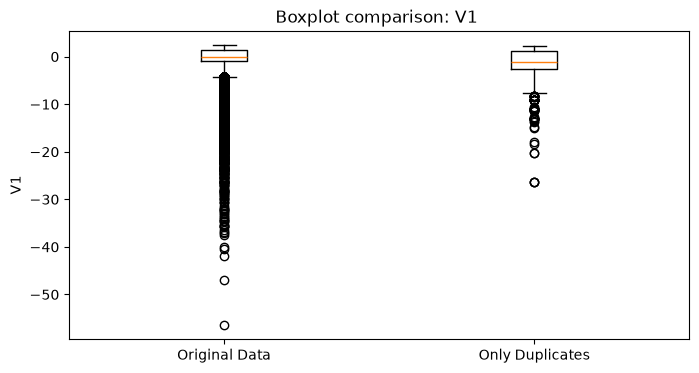

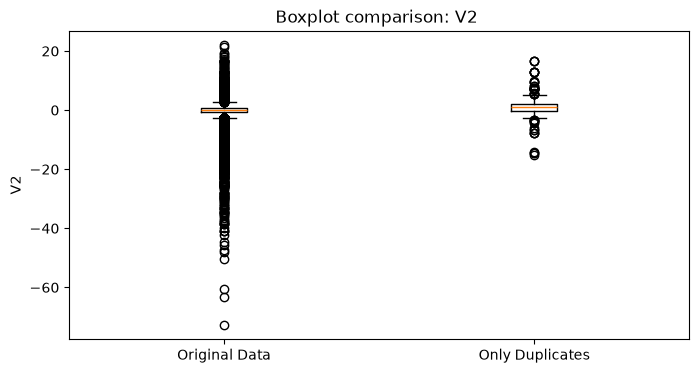

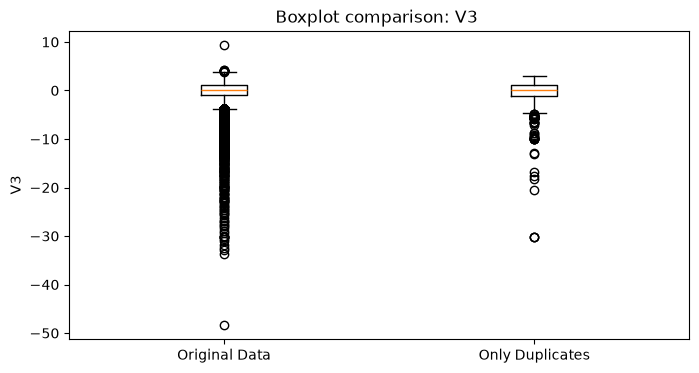

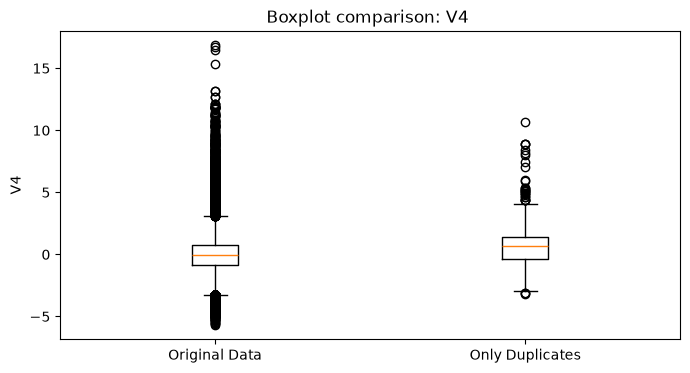

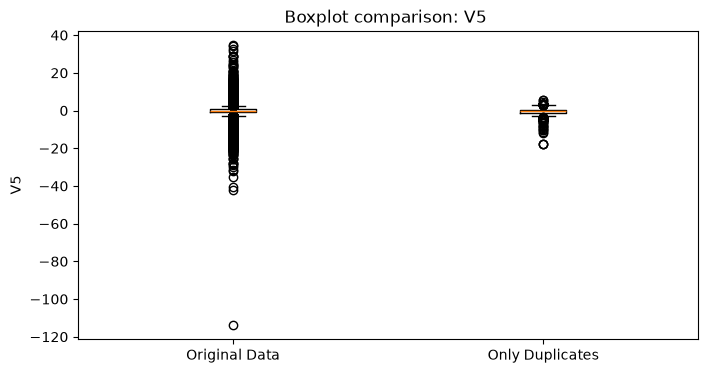

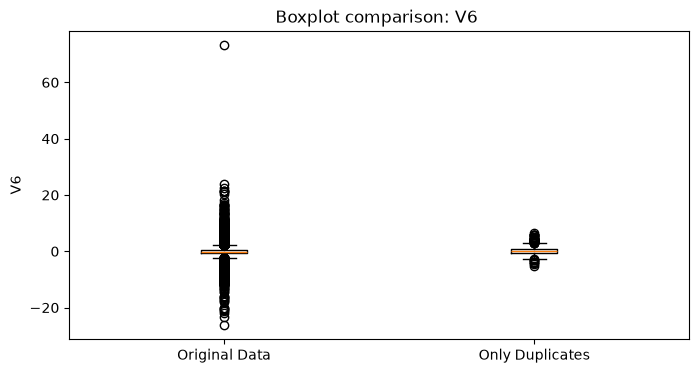

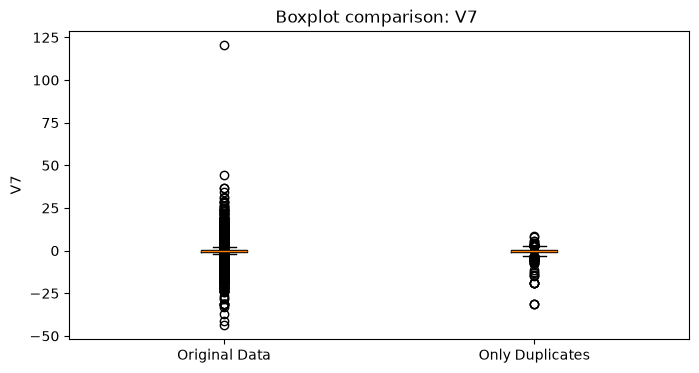

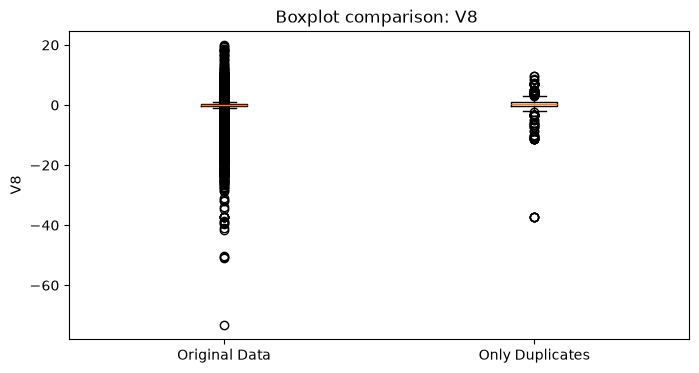

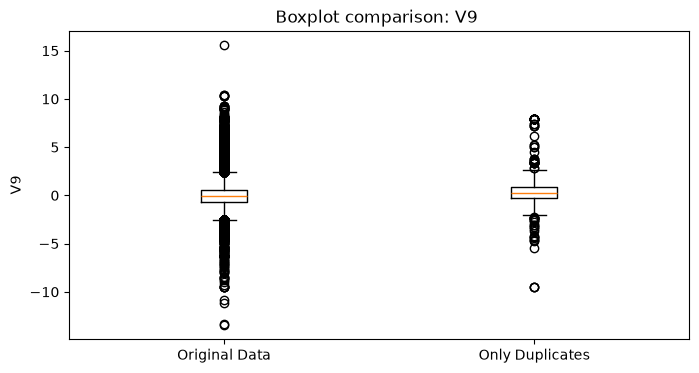

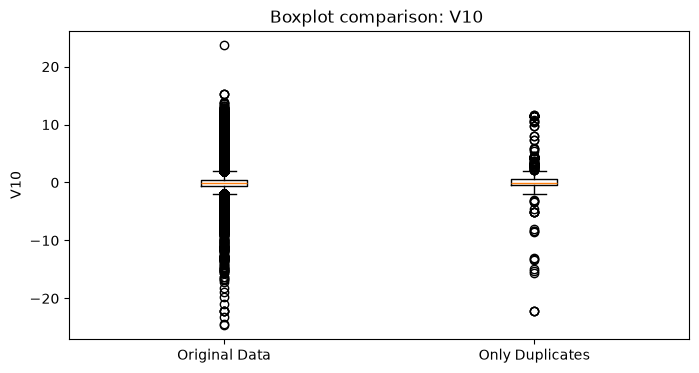

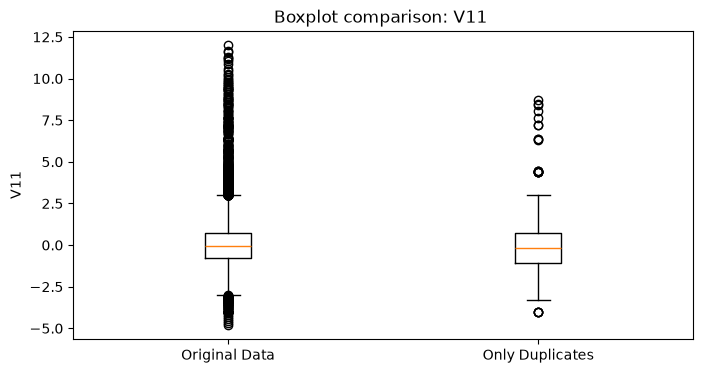

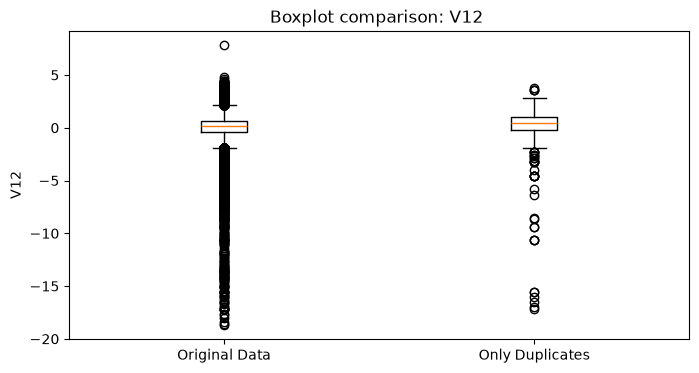

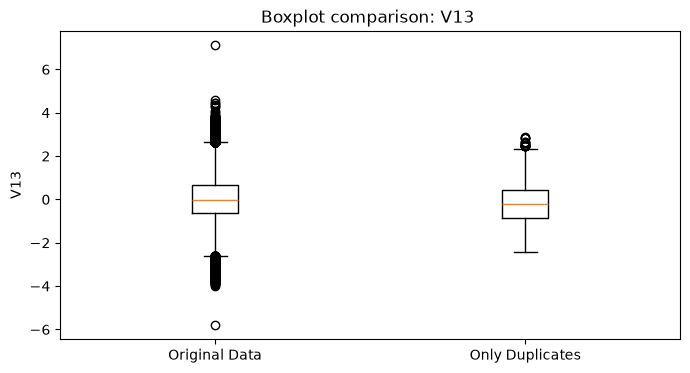

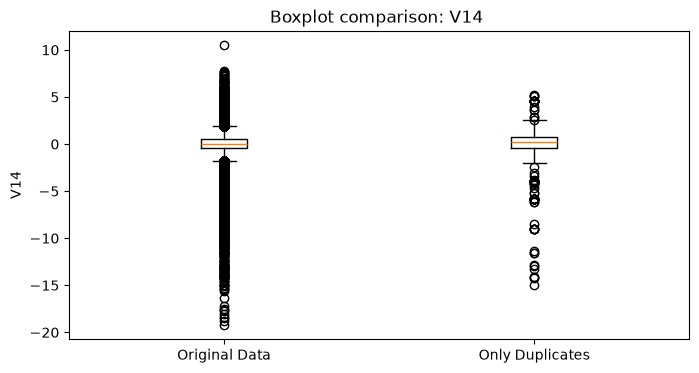

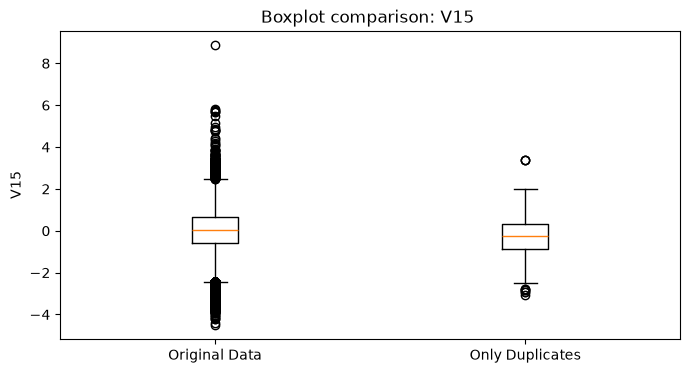

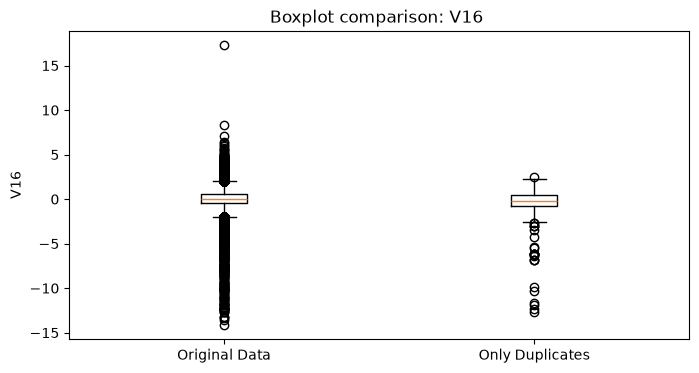

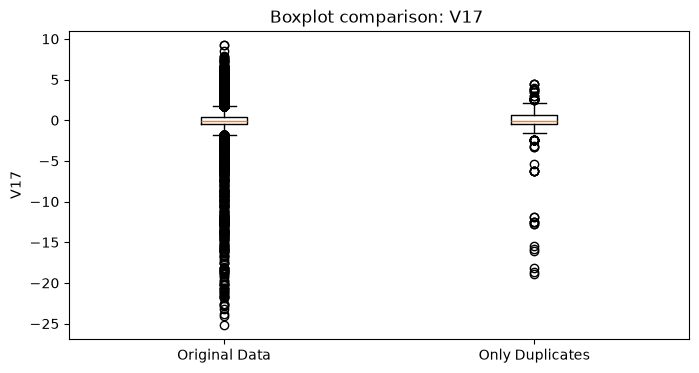

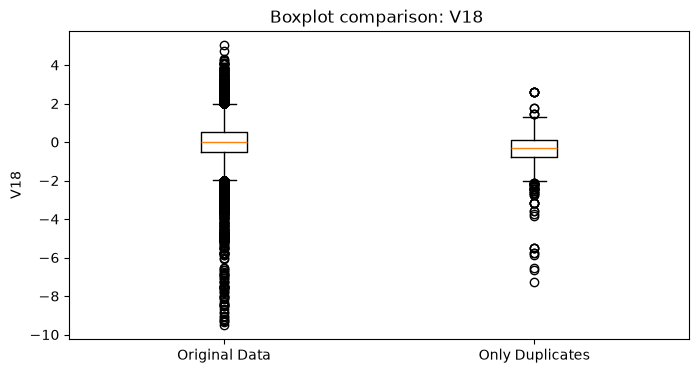

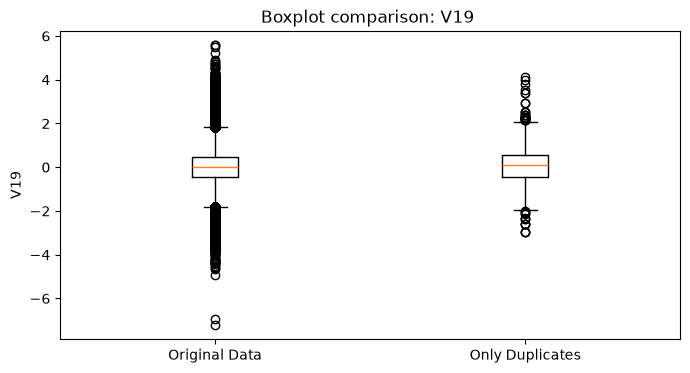

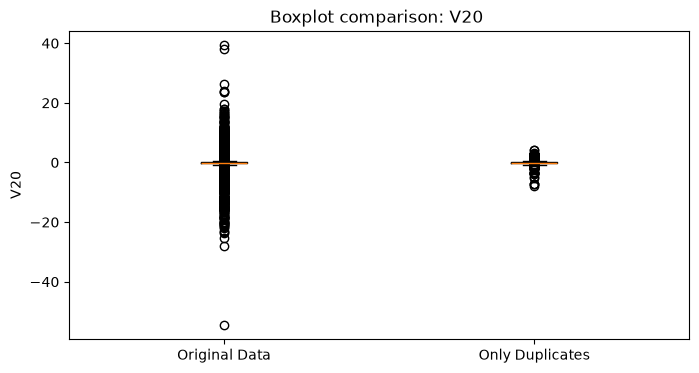

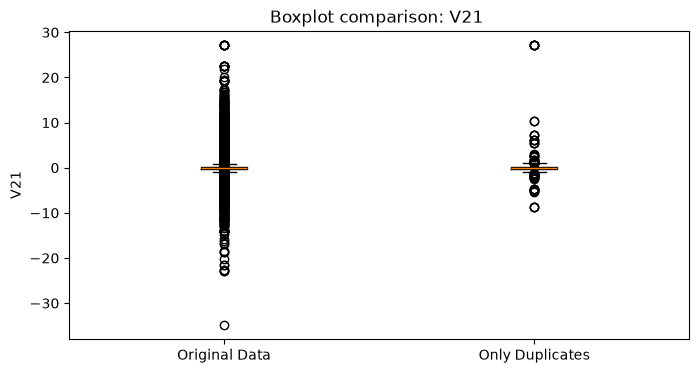

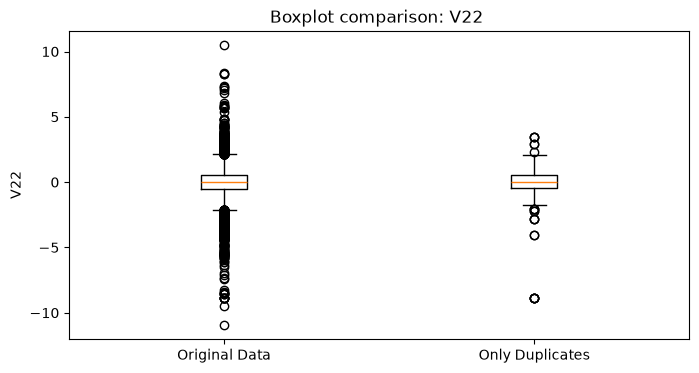

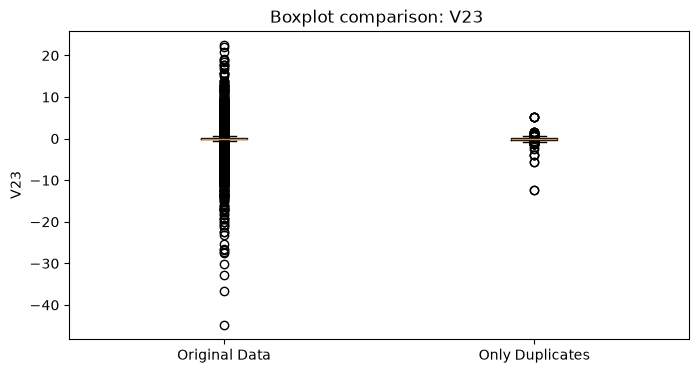

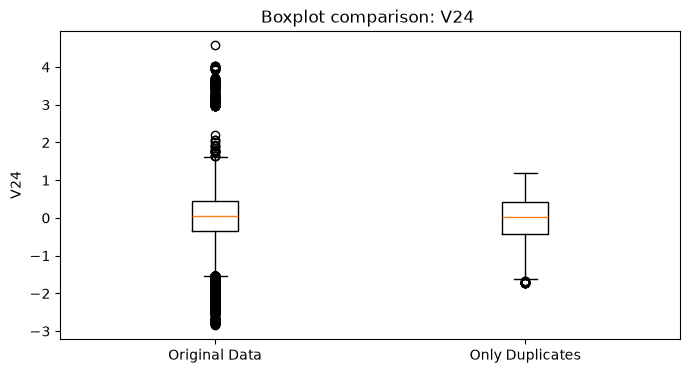

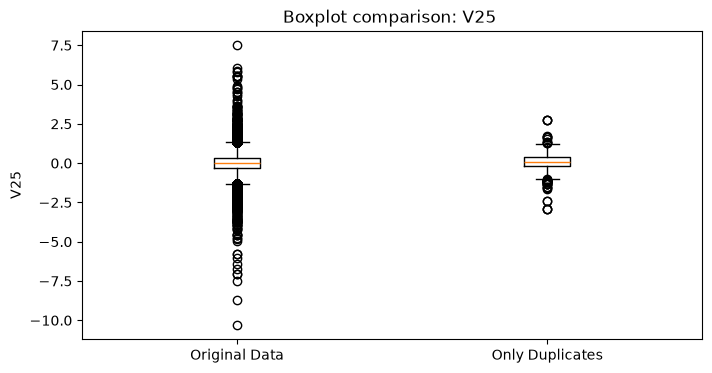

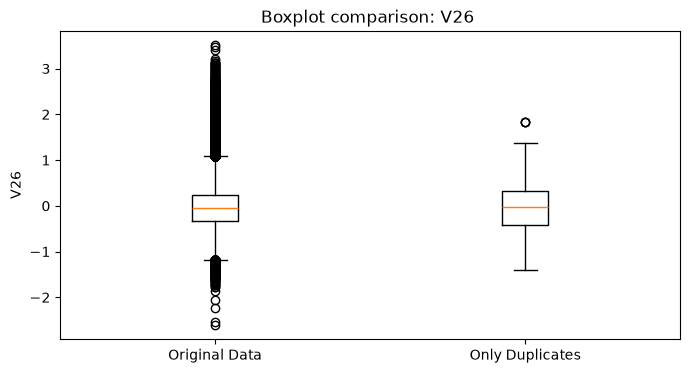

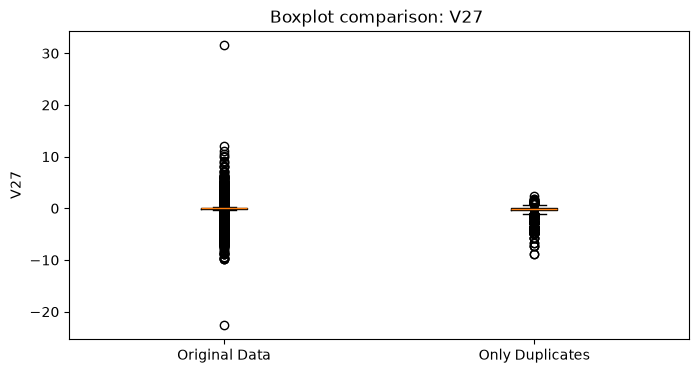

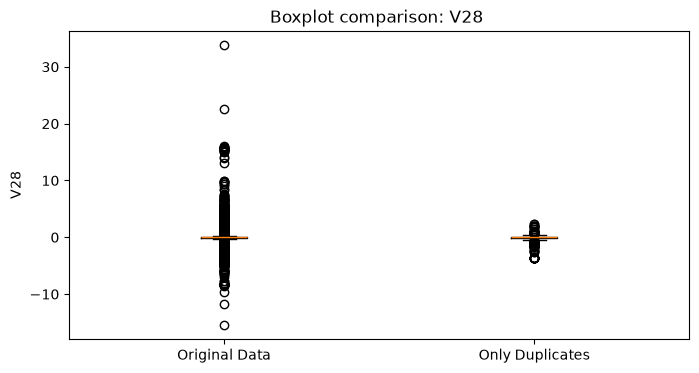

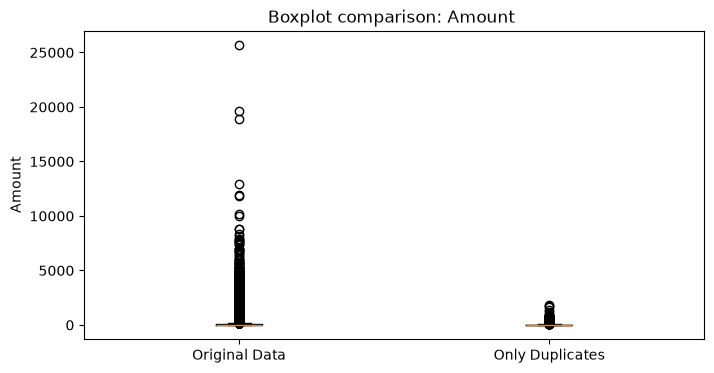

In [154]:
#9. Boxplot chart for all data and only duplicates

def boxplot_comparison(df_1, df_2, column_drop:list=False, boxplot_df_1_title="df_1", boxplot_df_2_title="df_2"):

    if column_drop:
        if type(column_drop) is not list:
                raise TypeError("column_drop must be a list of column names to drop from both dataframes.")
        
        for col in column_drop:
            if col not in df_1.columns or col not in df_2.columns:
                raise KeyError(f"Column '{col}' not found in one or both of the dataframes.")
            df_1 = df_1.drop(columns=[col])
            df_2=df_2.drop(columns=[col])
    
    for col in df_1.columns:
        plt.figure(figsize=(8, 4))

        plt.boxplot(
            [
                df_1[col],
                df_2[col]
            ],
            tick_labels=[boxplot_df_1_title, boxplot_df_2_title]
        )

        plt.title(f"Boxplot comparison: {col} ")
        plt.ylabel(col)
        plt.show()
    

credit_card_data_only_duplicates = credit_card_data[credit_card_data.duplicated()]

comparison_orginal_data_and_only_duplicates = boxplot_comparison(
     credit_card_data,
     credit_card_data_only_duplicates, 
     column_drop=["Class", "Time"], 
     boxplot_df_1_title="Original Data", 
     boxplot_df_2_title="Only Duplicates"
)

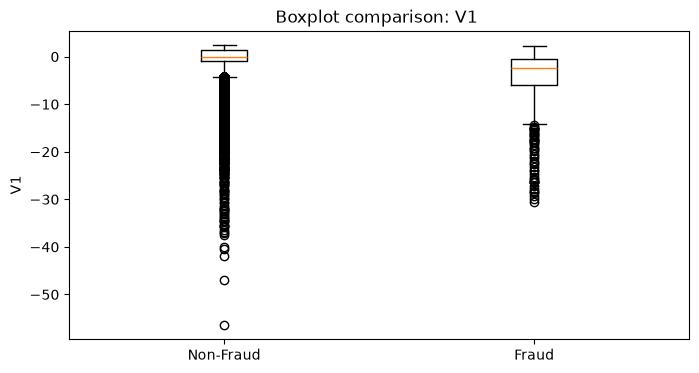

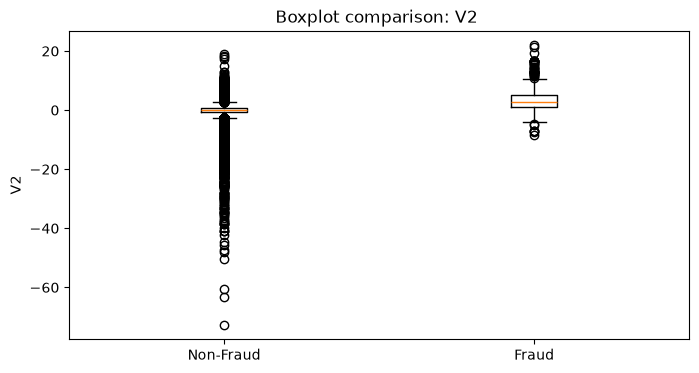

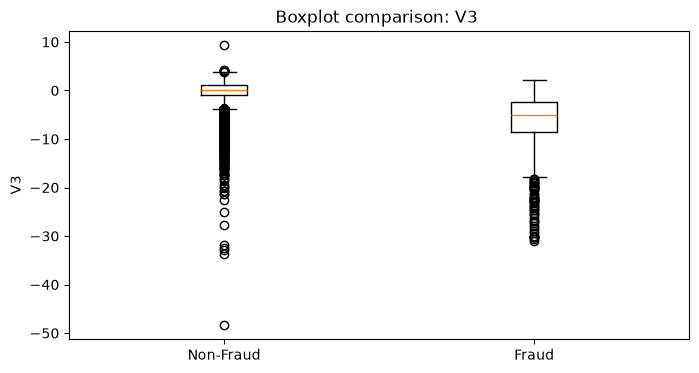

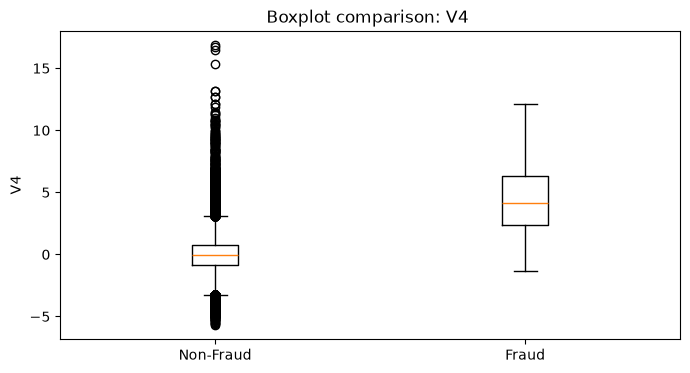

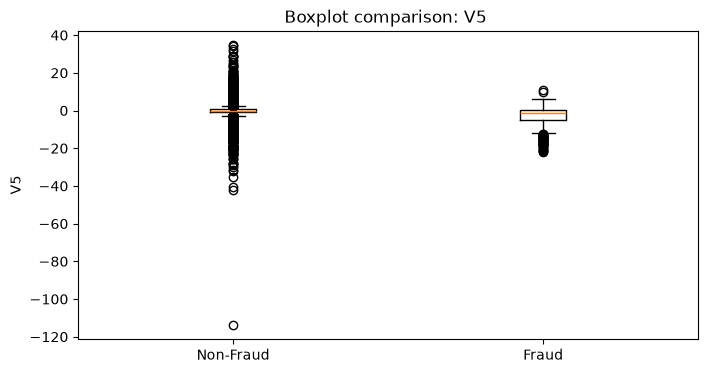

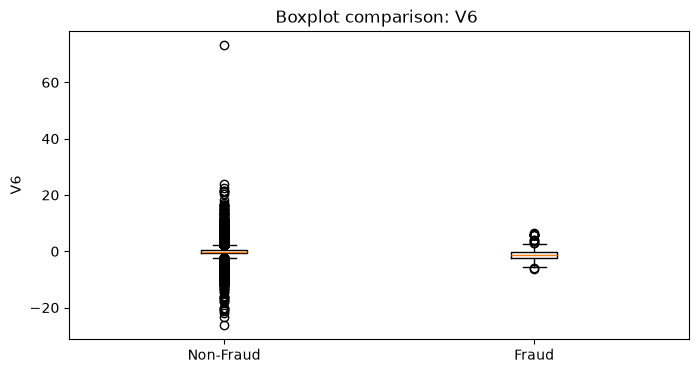

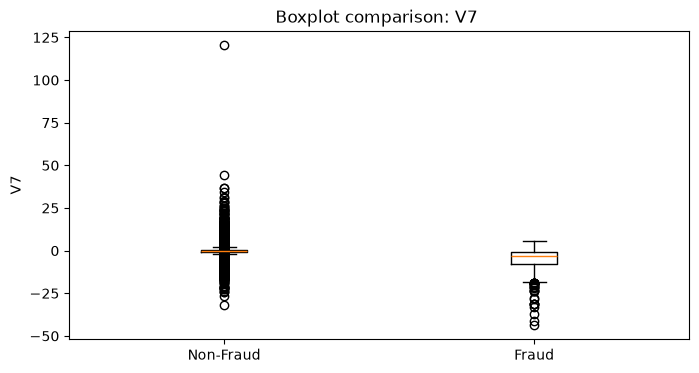

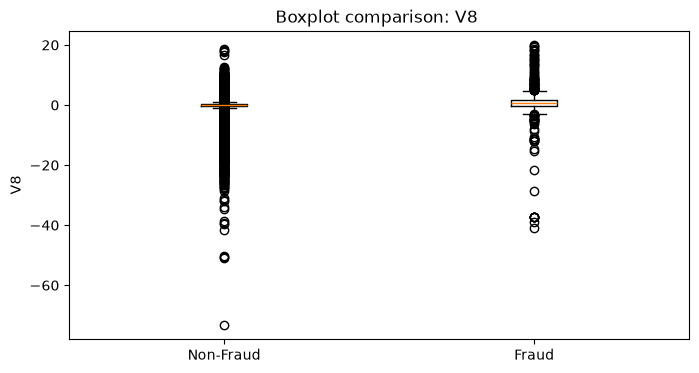

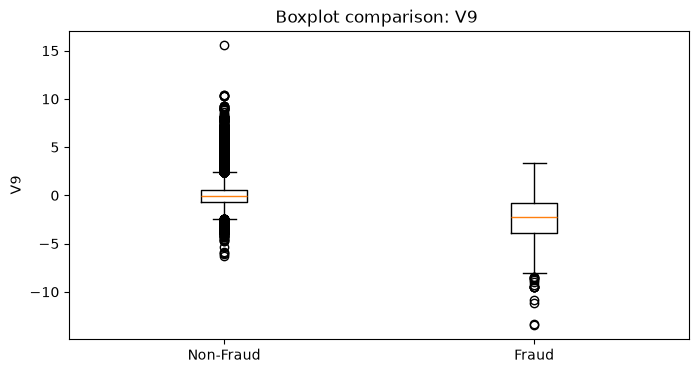

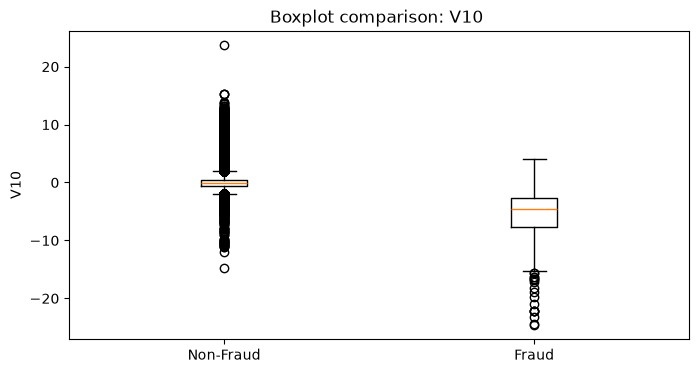

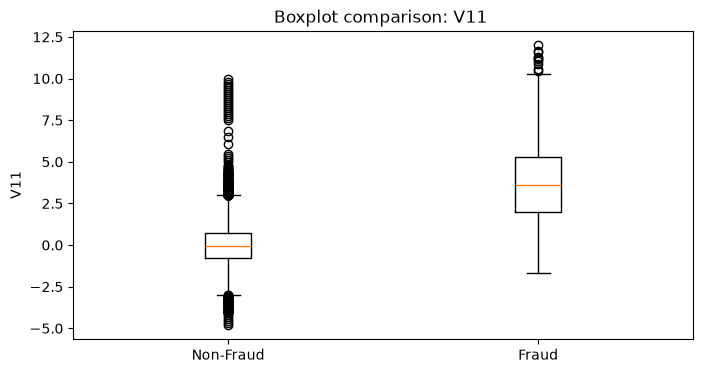

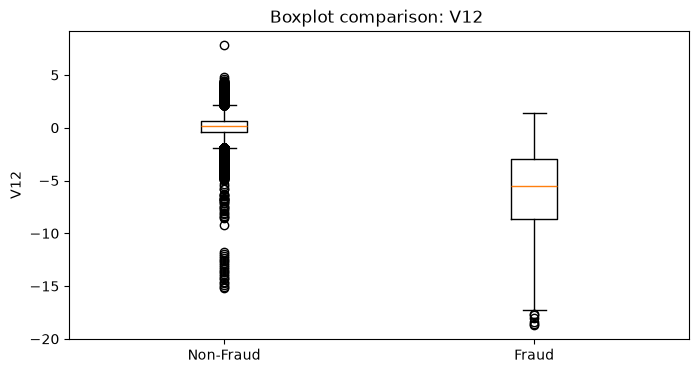

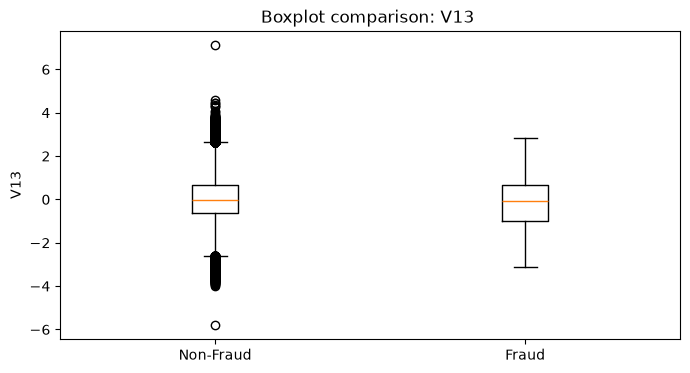

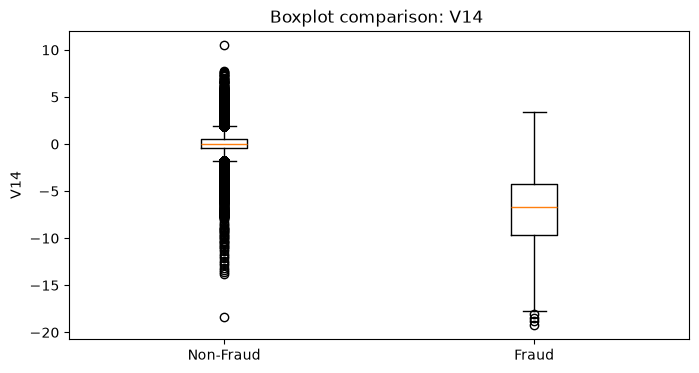

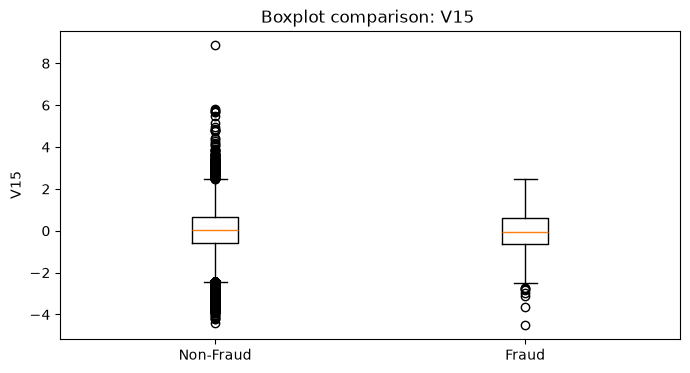

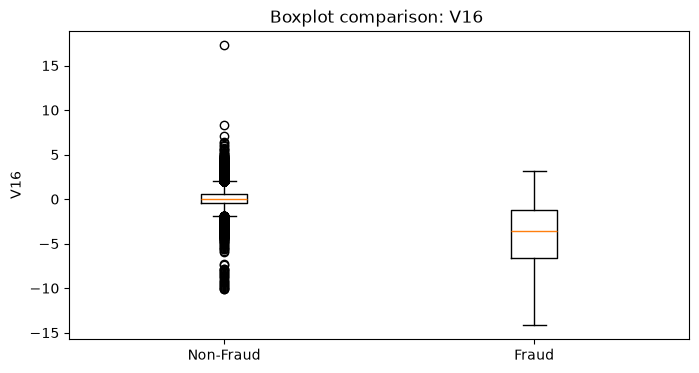

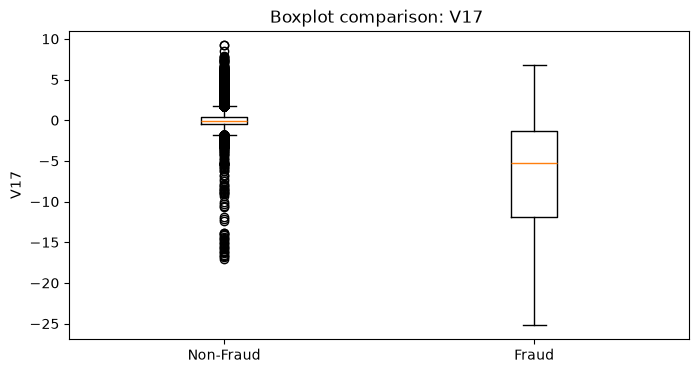

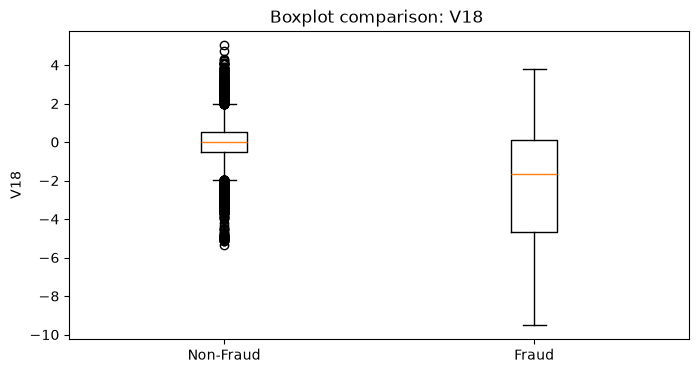

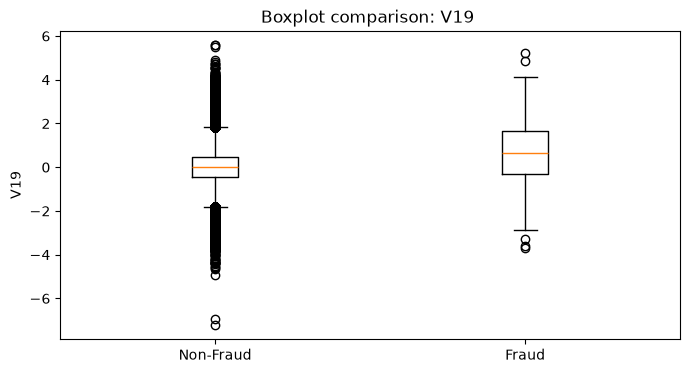

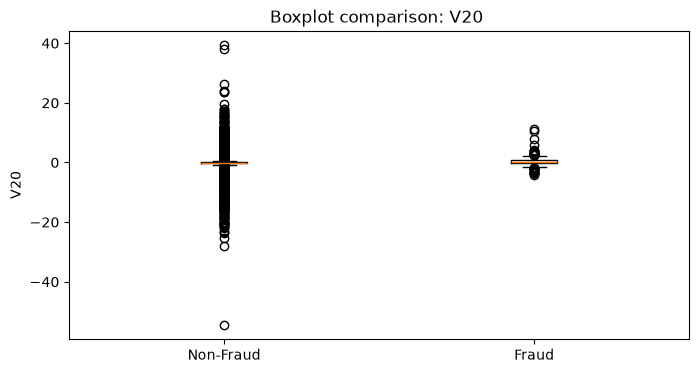

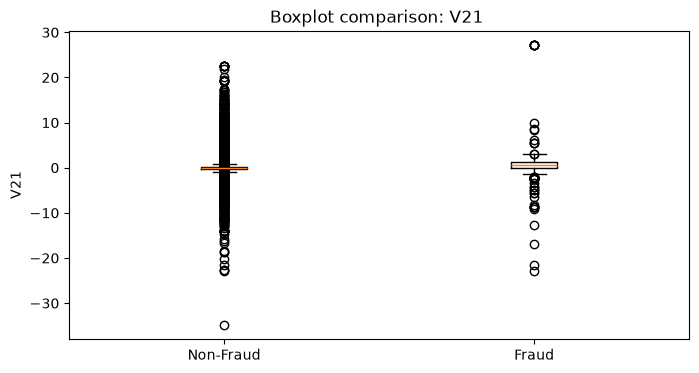

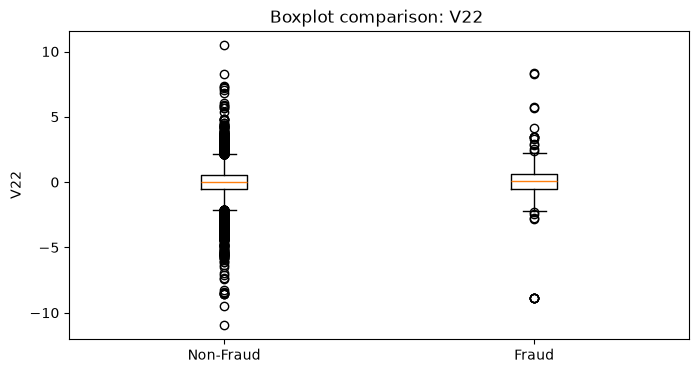

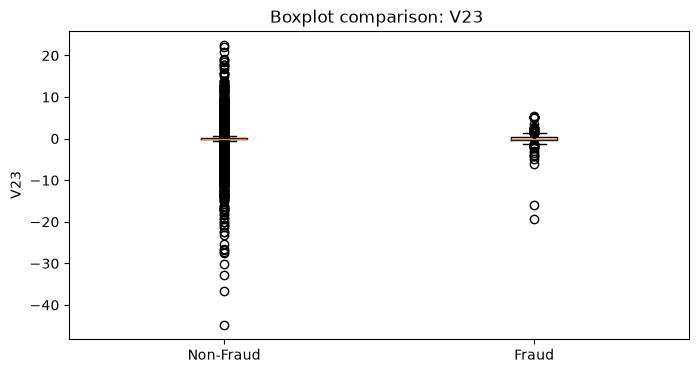

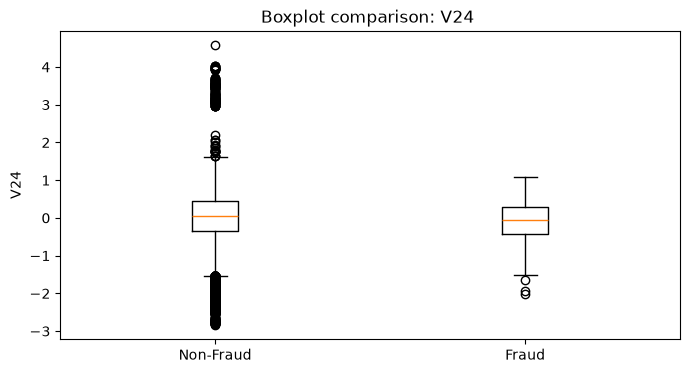

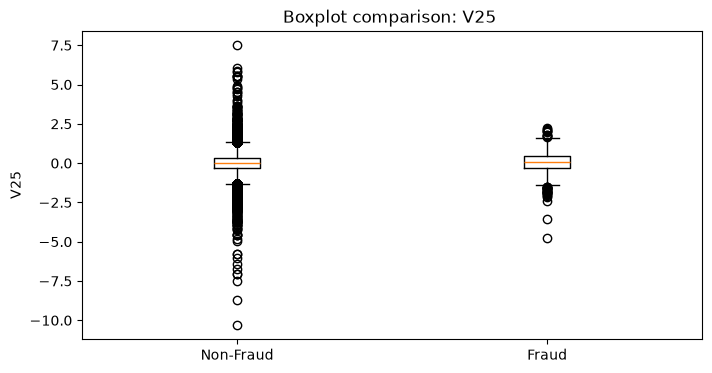

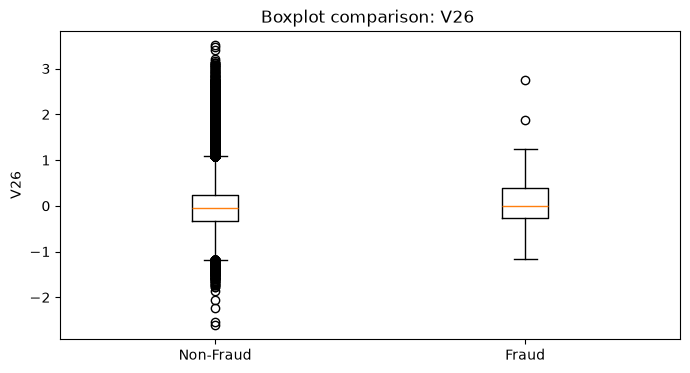

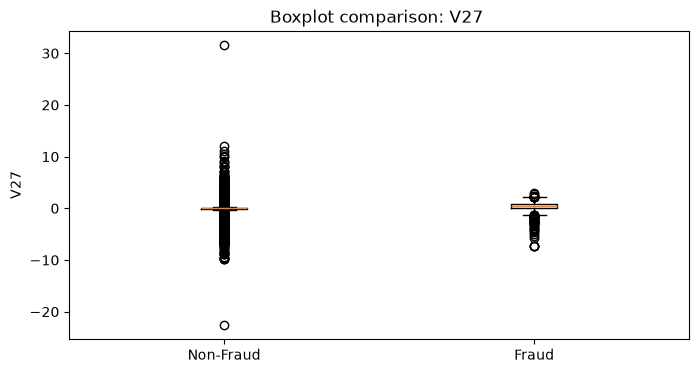

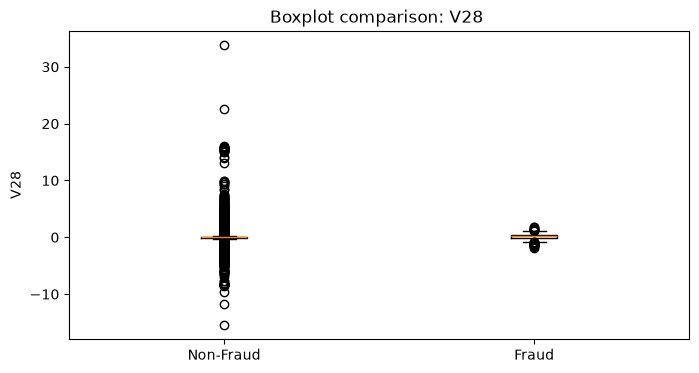

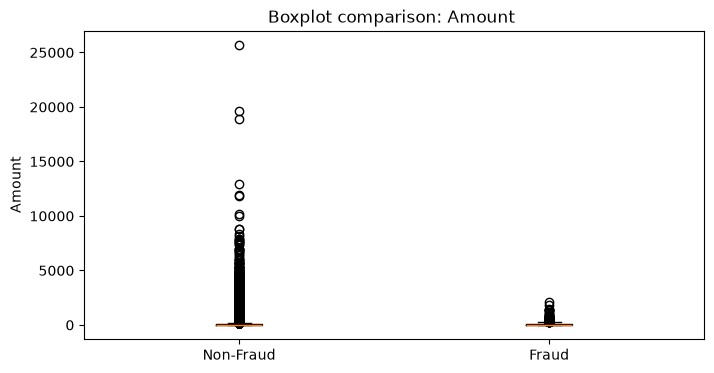

In [155]:
#10. Boxplot comparison for each feature between non-fraud and fraud transactions

credit_card_data_fraud = credit_card_data[credit_card_data["Class"] == 1]
credit_card_data_non_fraud = credit_card_data[credit_card_data["Class"] == 0]

comparison_orginal_data_and_only_duplicates = boxplot_comparison(
     credit_card_data_non_fraud,
     credit_card_data_fraud, 
     column_drop=["Class", "Time"], 
     boxplot_df_1_title="Non-Fraud", 
     boxplot_df_2_title="Fraud"
)

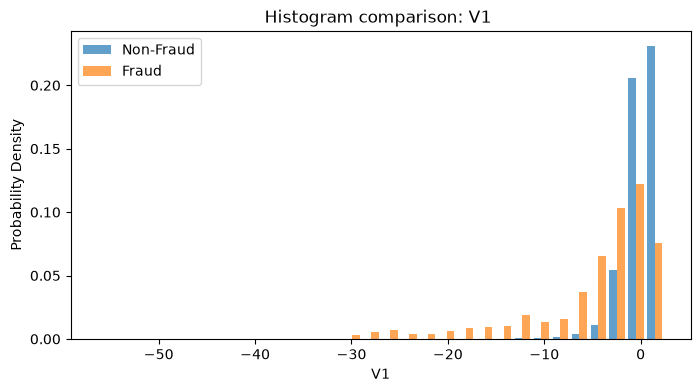

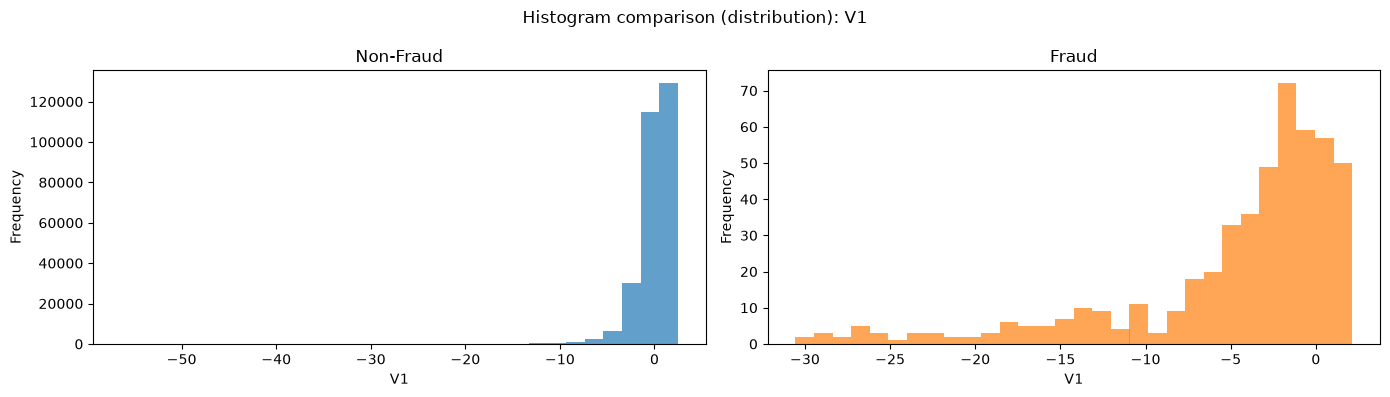

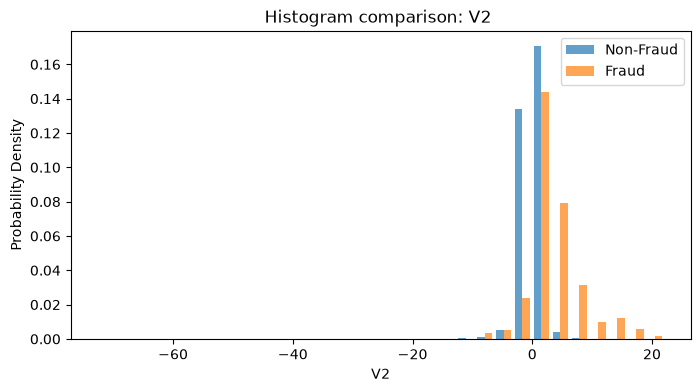

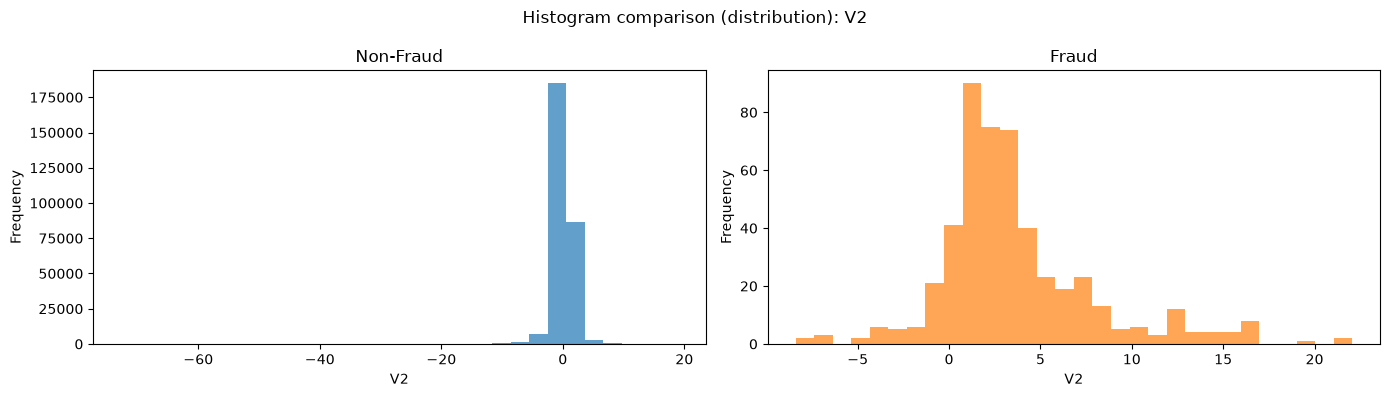

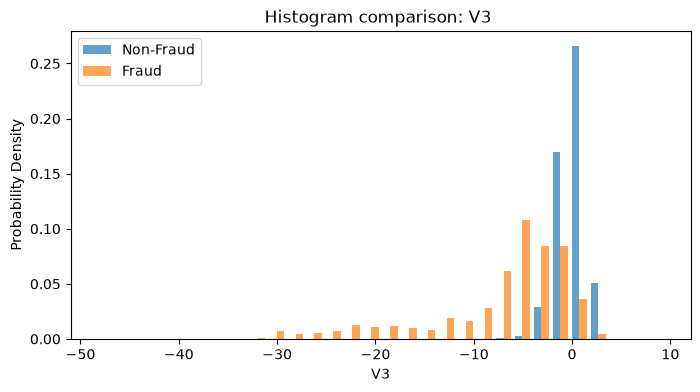

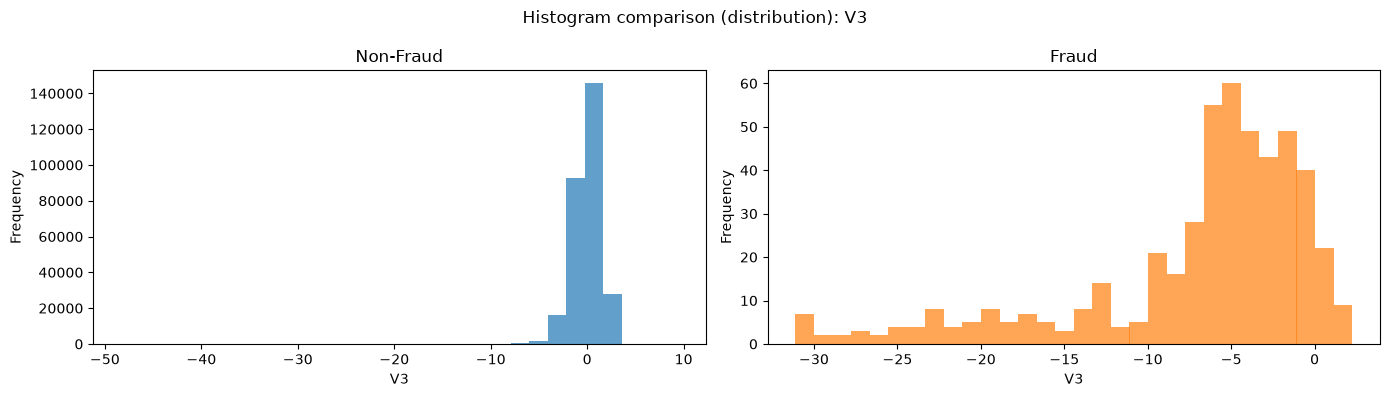

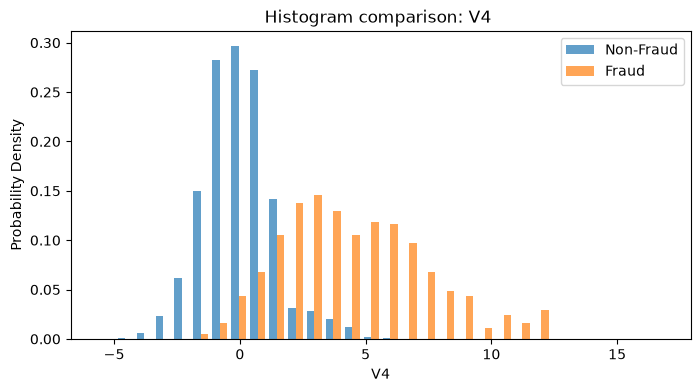

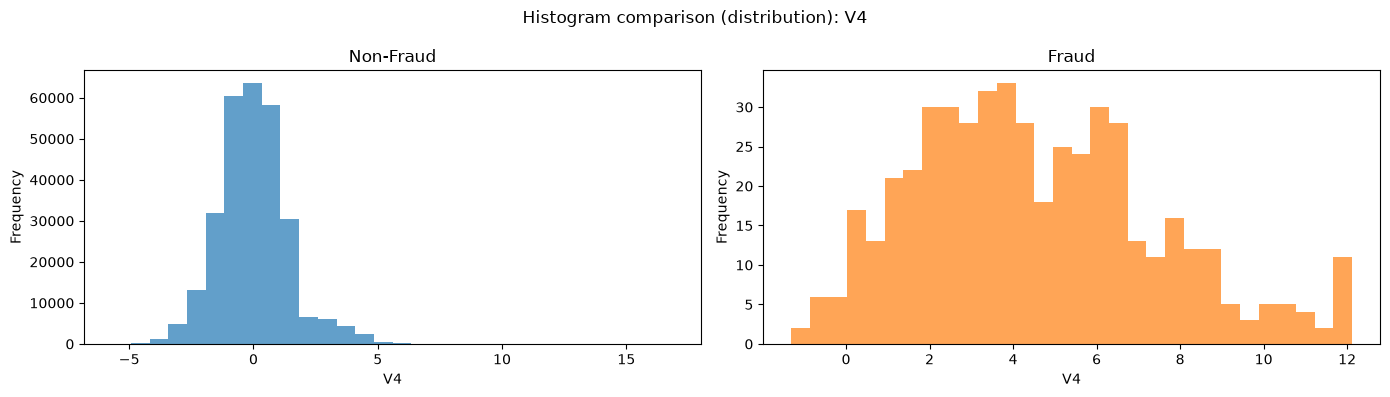

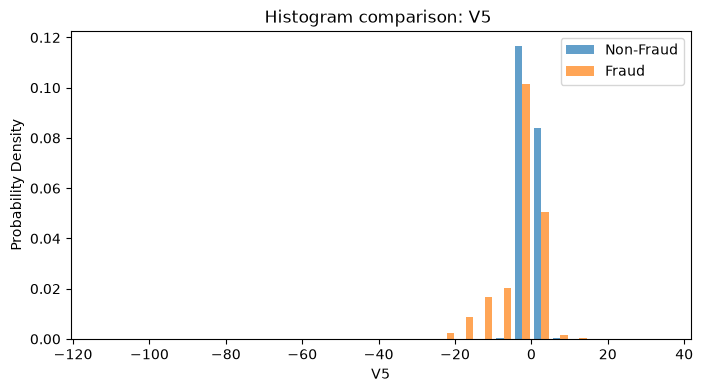

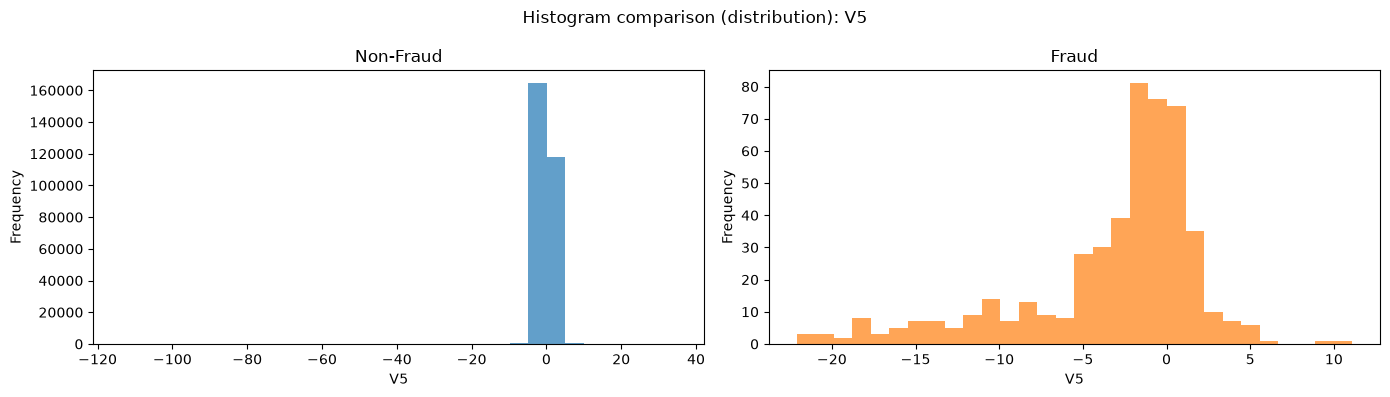

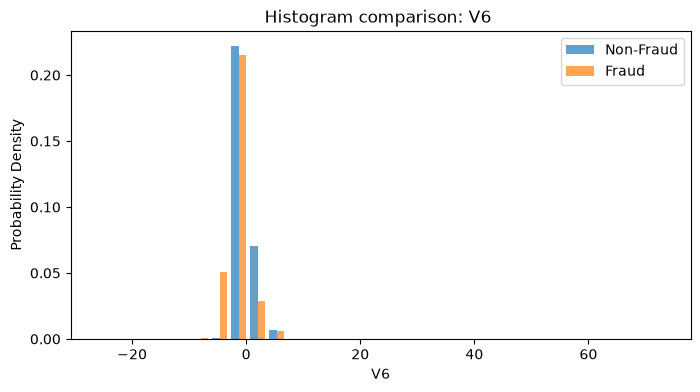

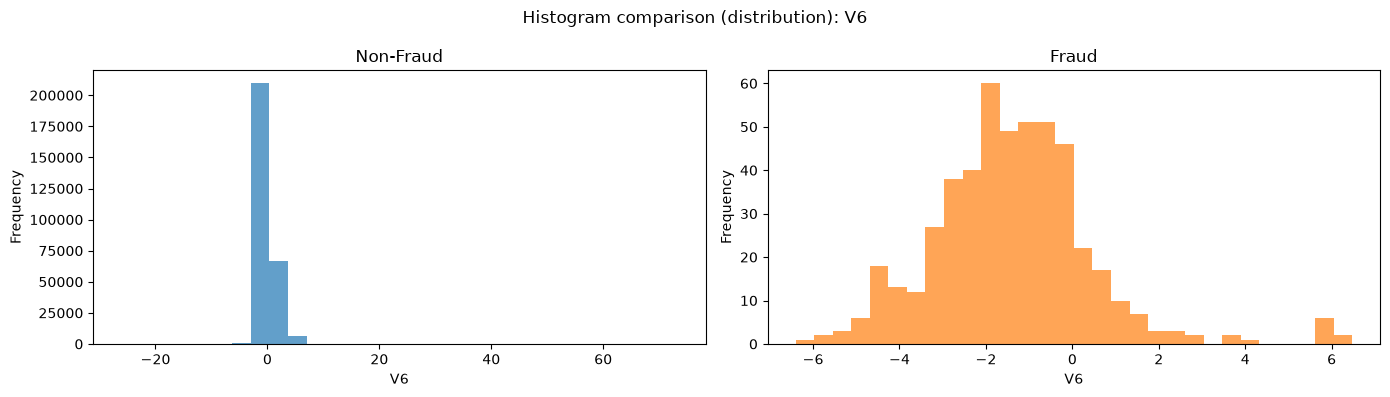

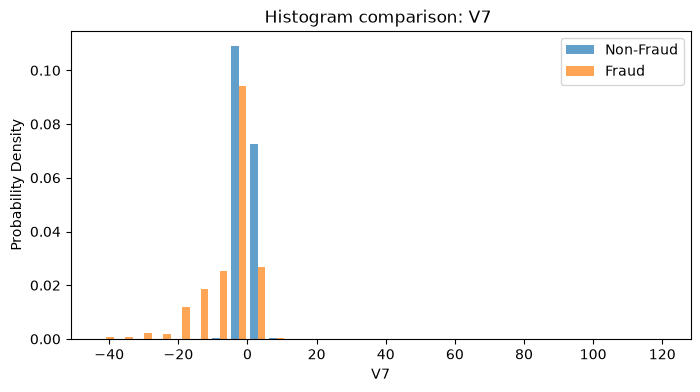

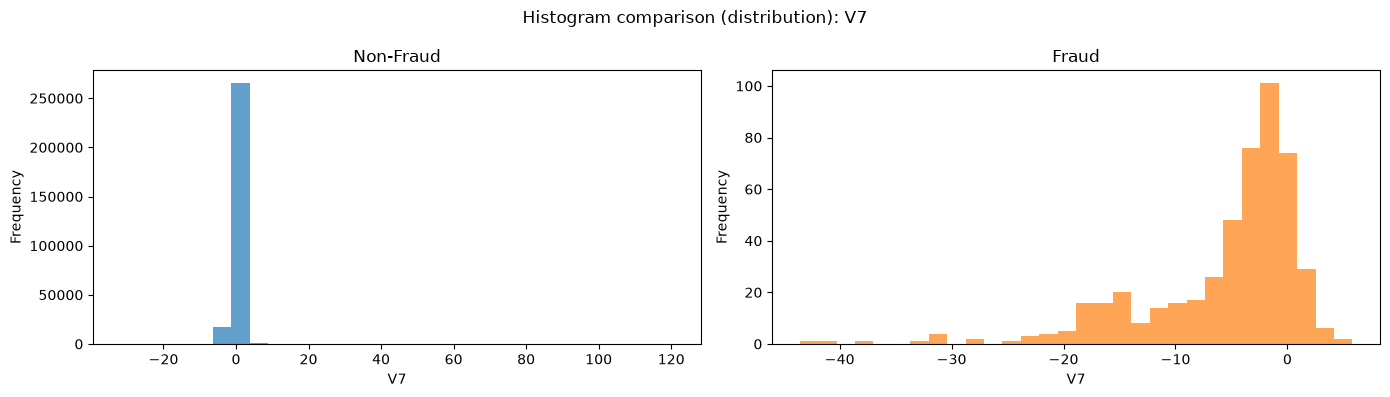

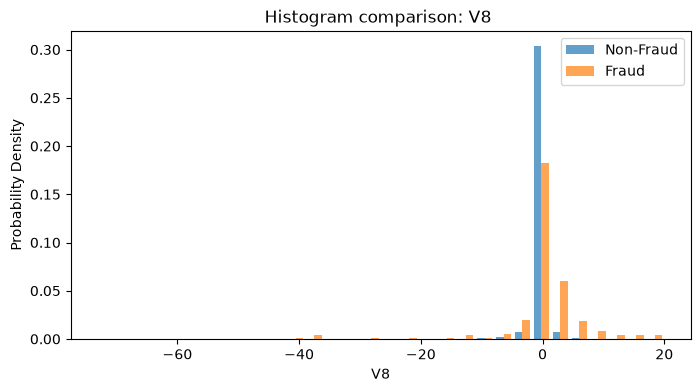

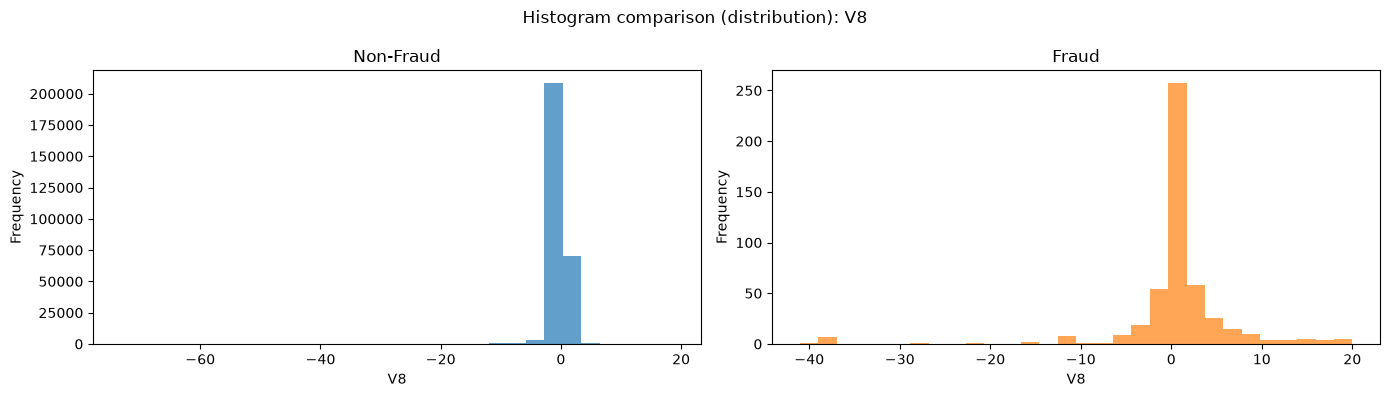

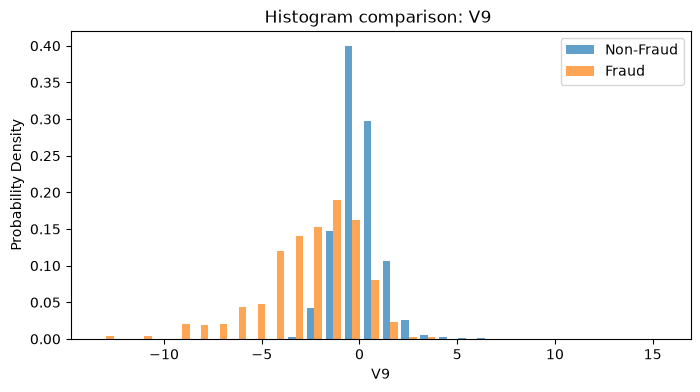

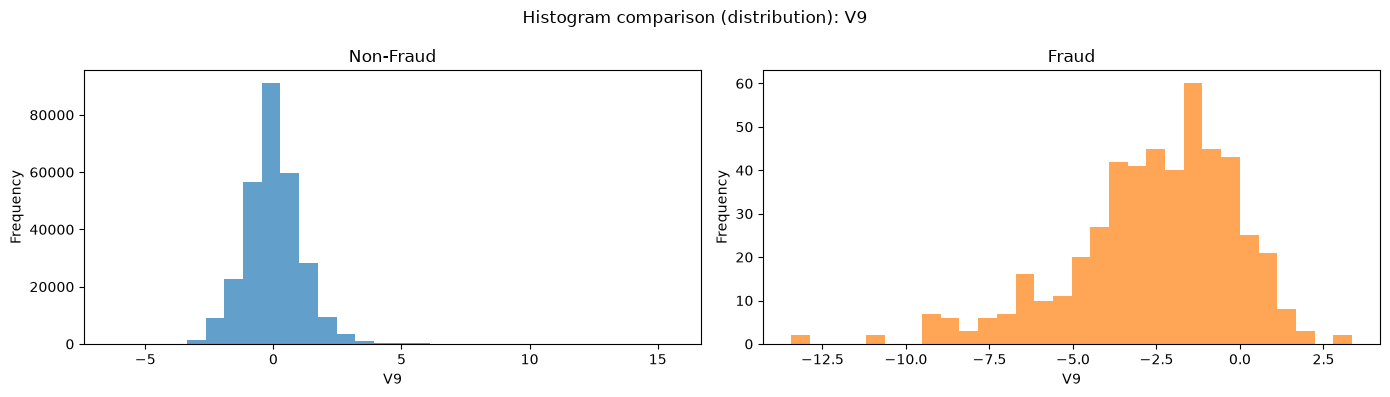

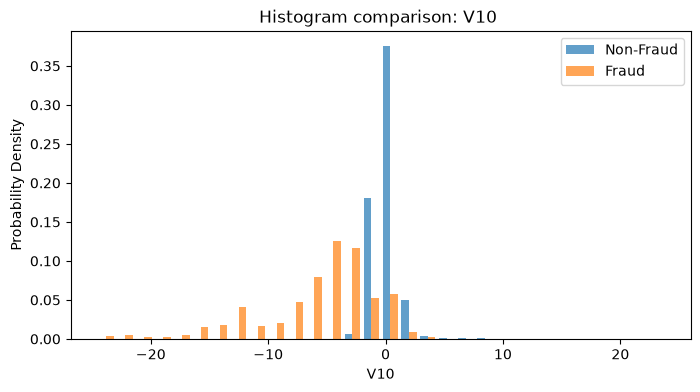

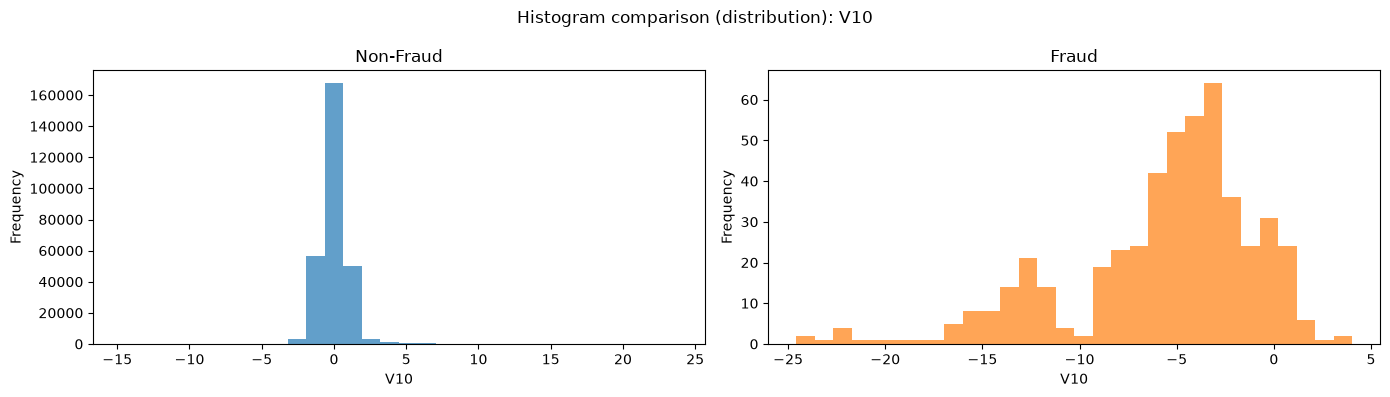

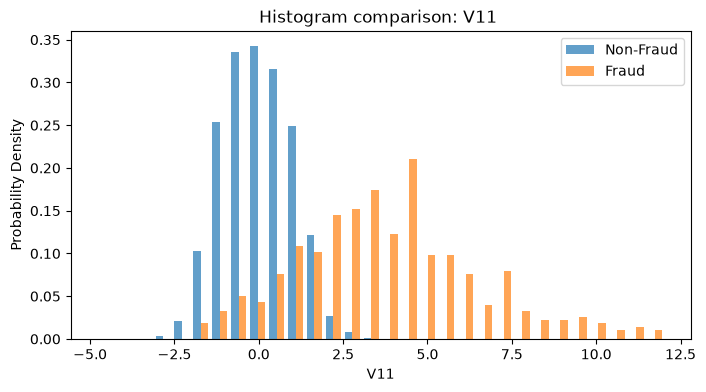

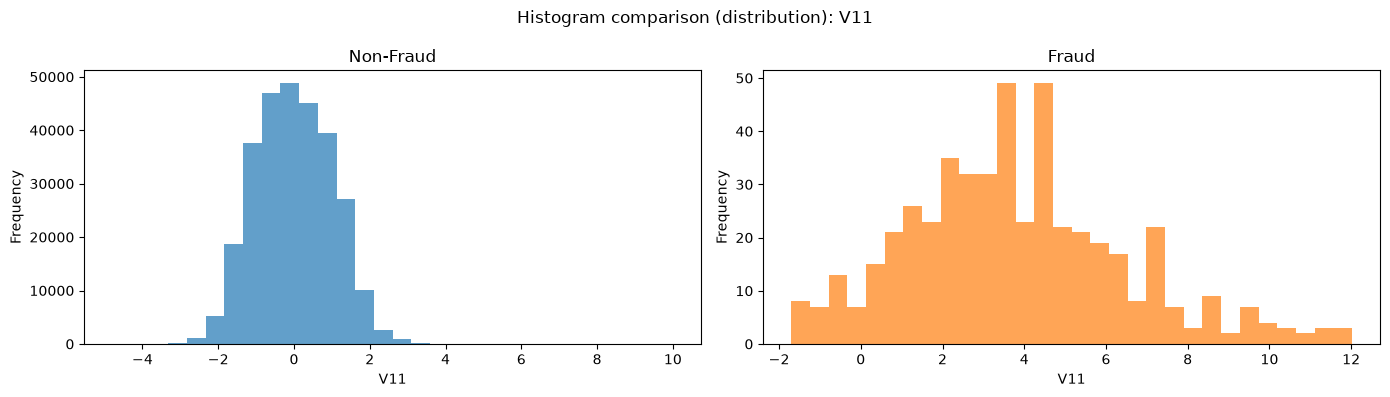

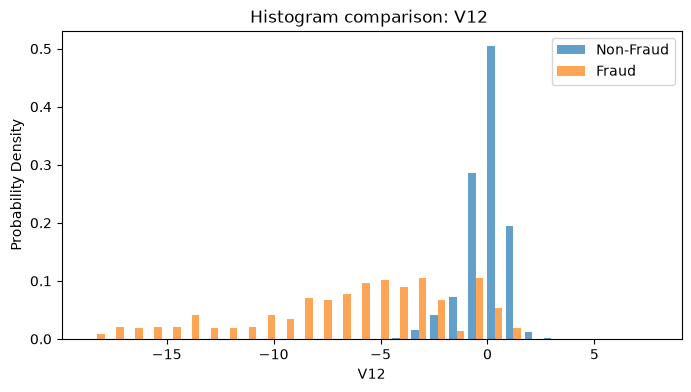

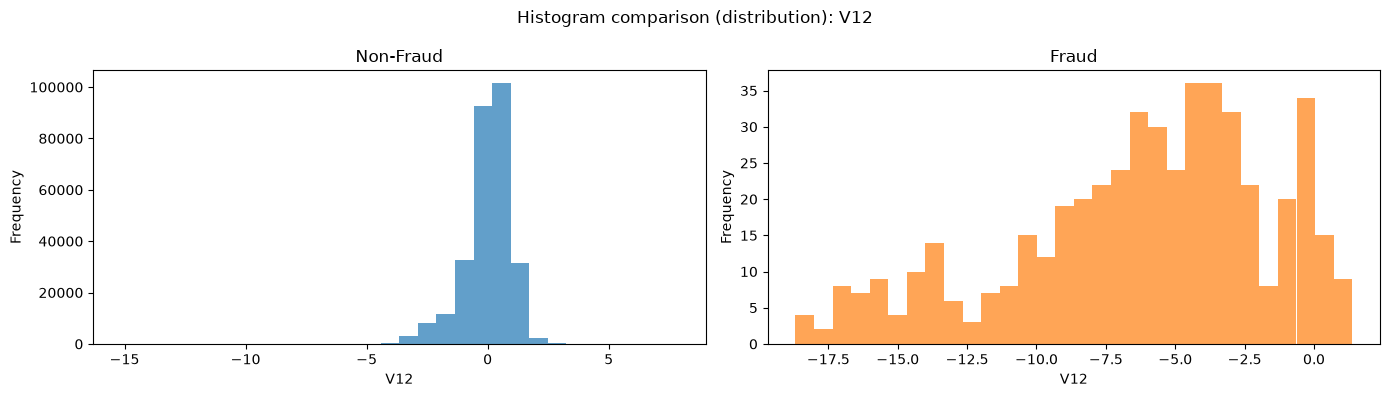

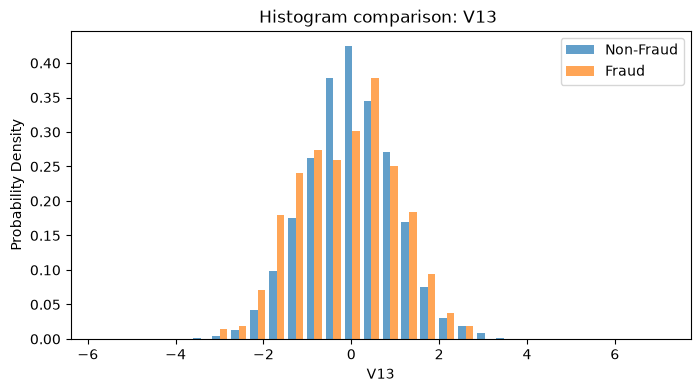

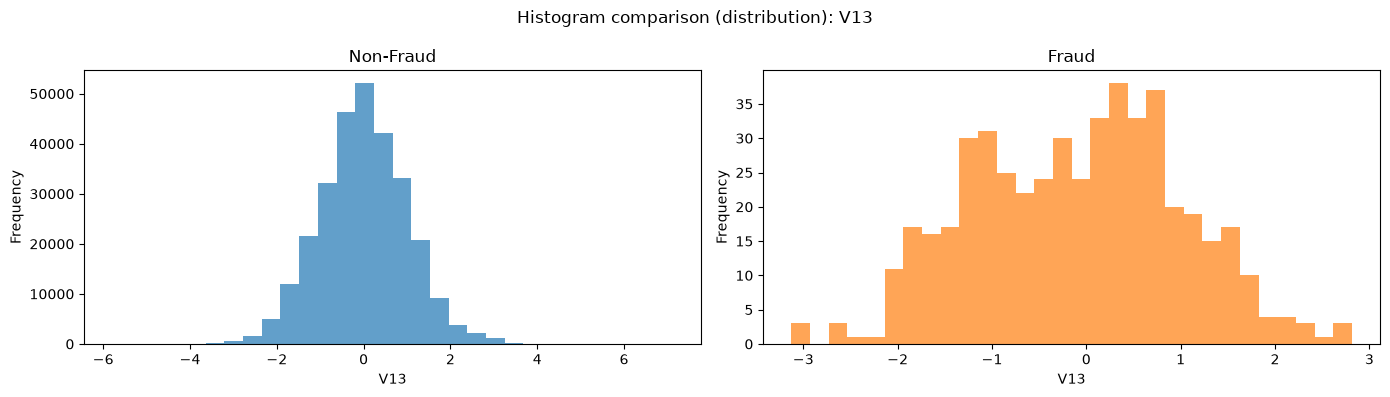

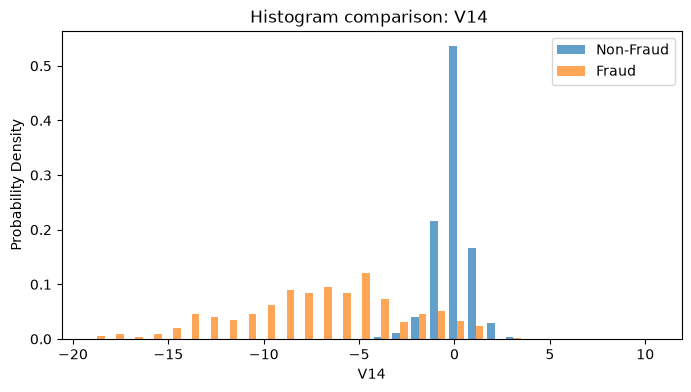

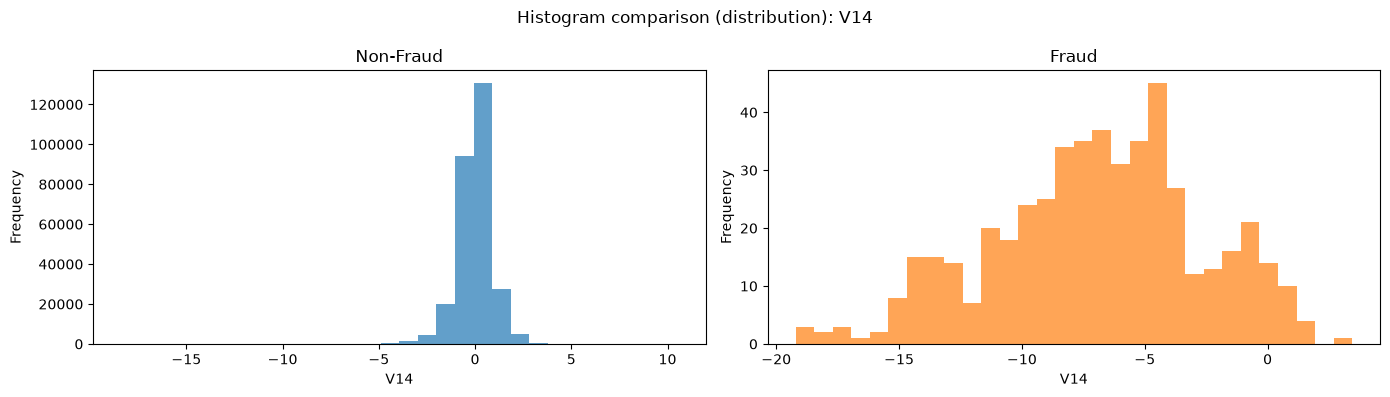

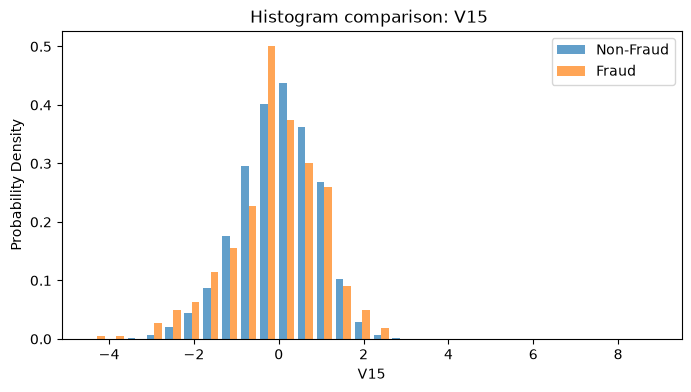

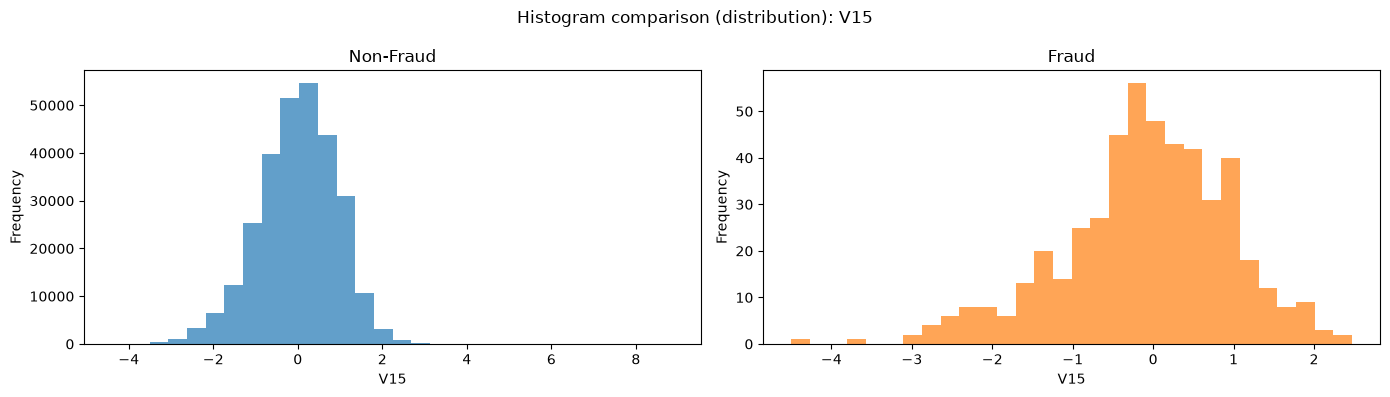

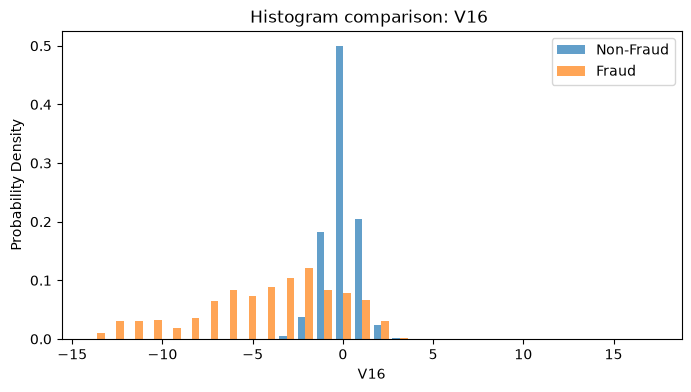

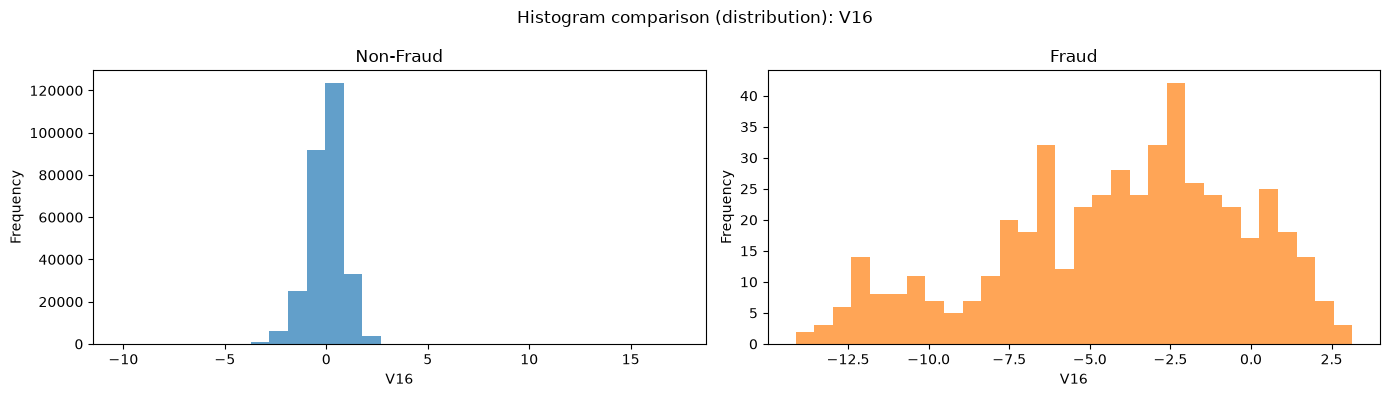

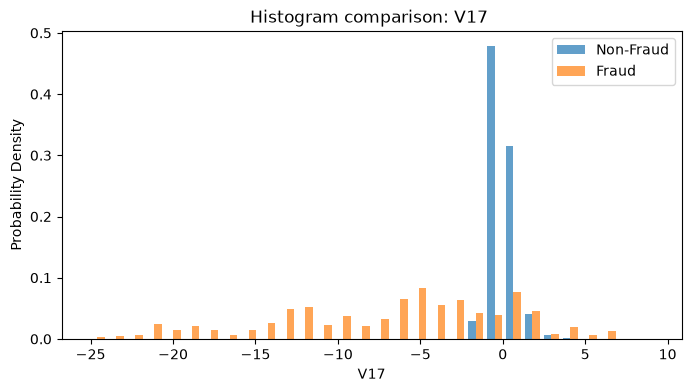

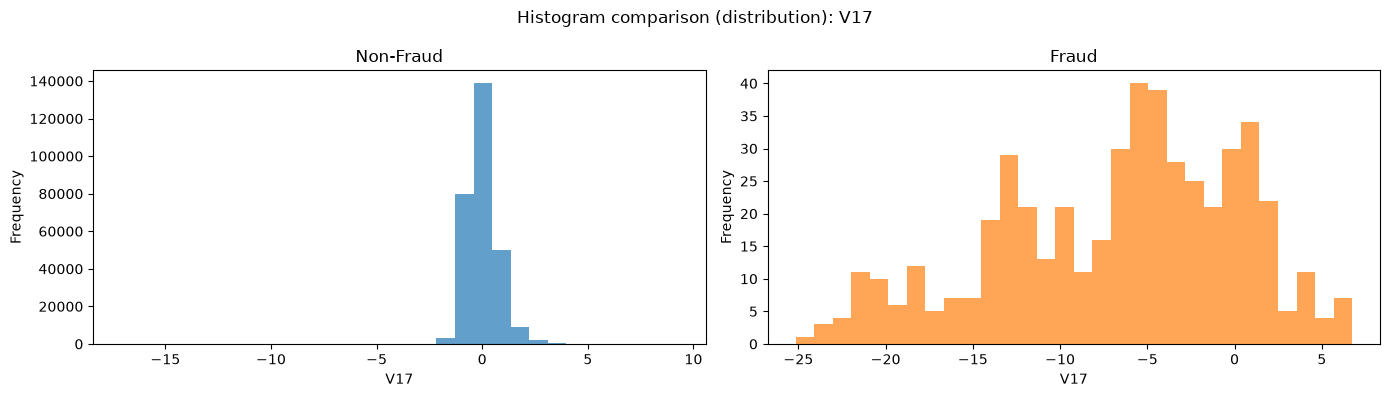

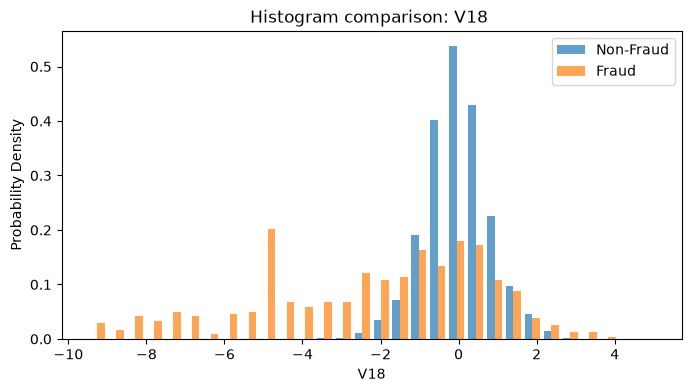

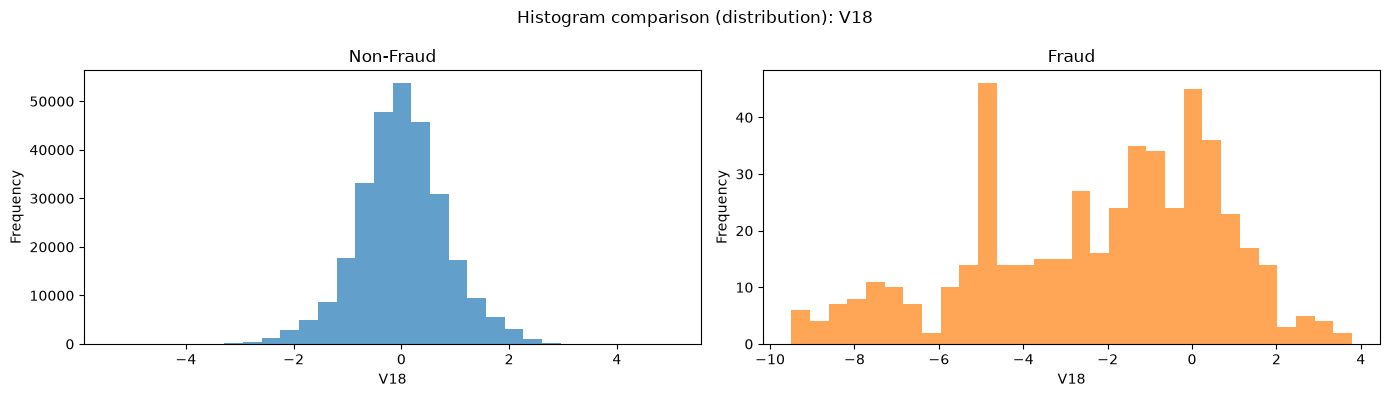

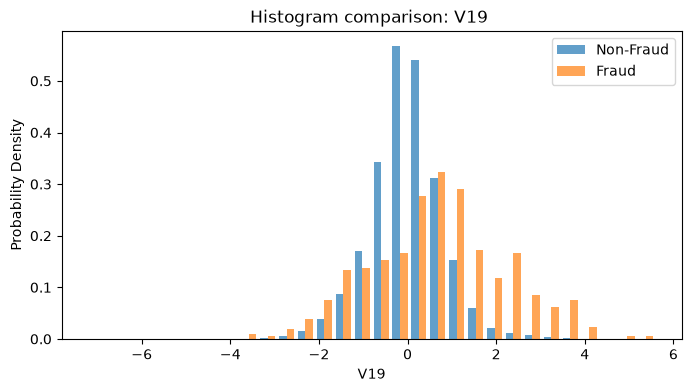

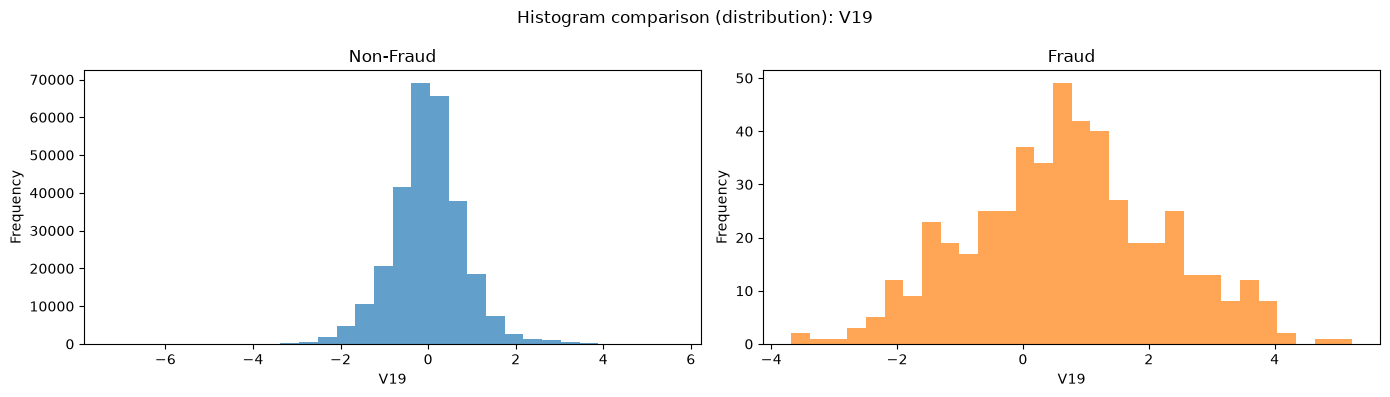

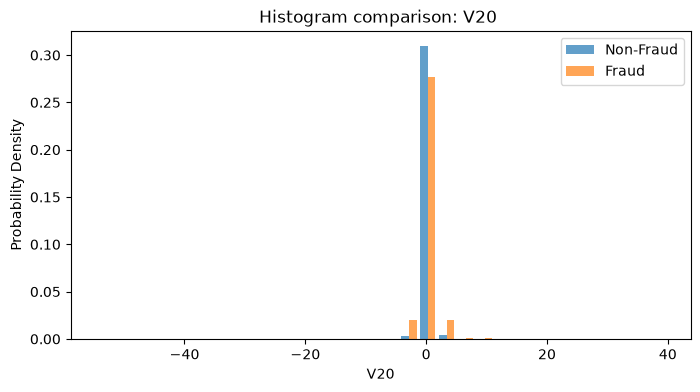

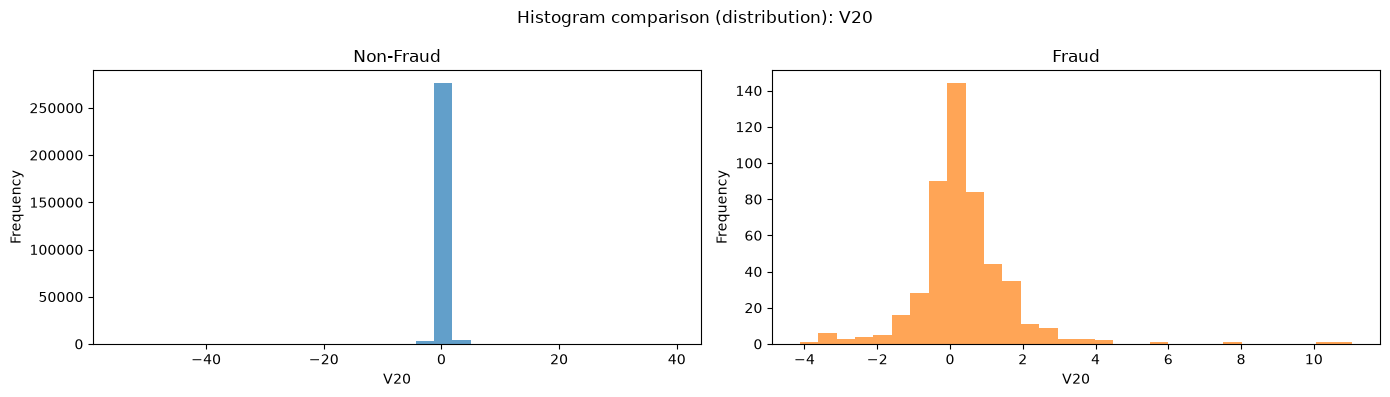

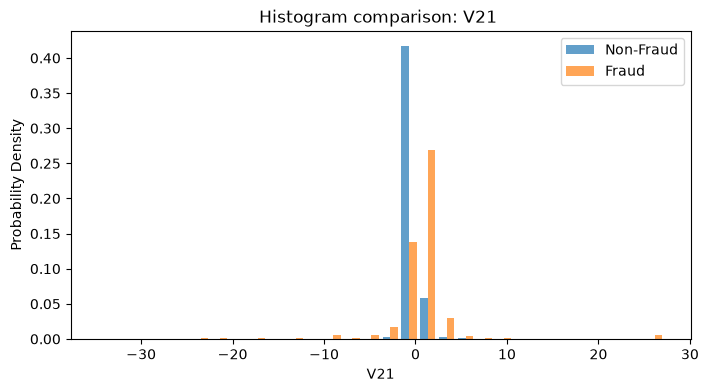

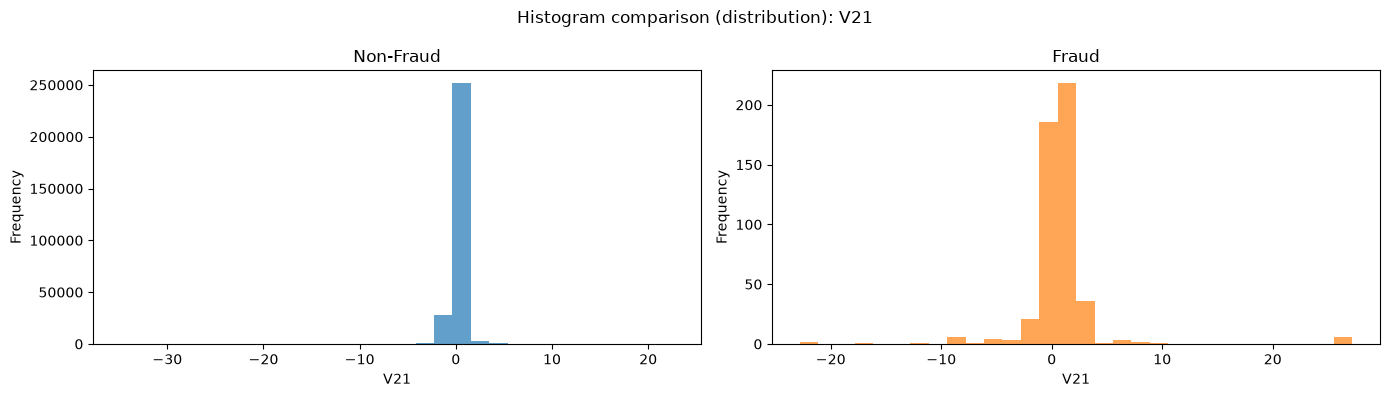

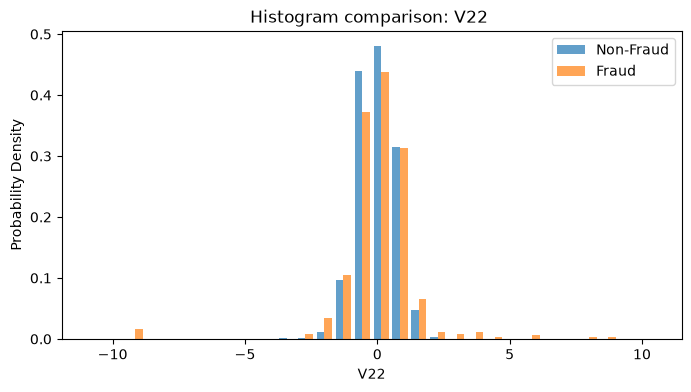

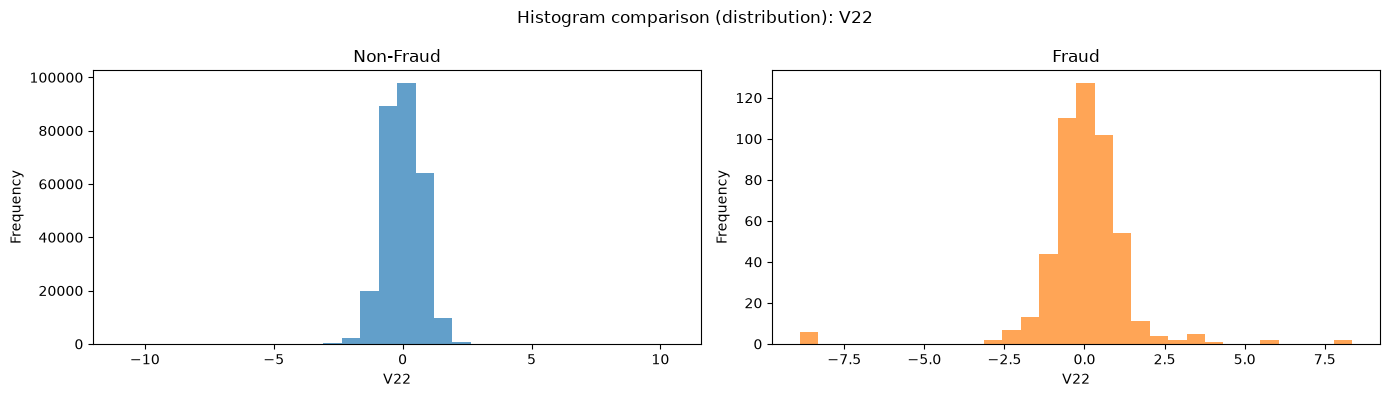

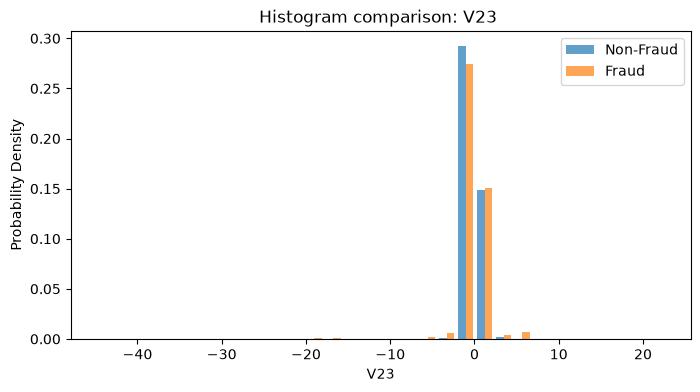

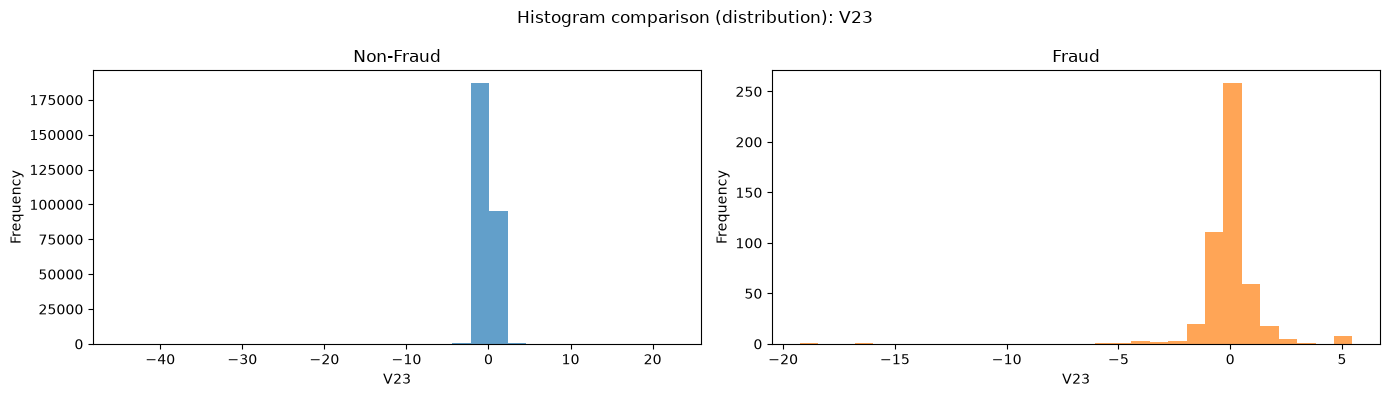

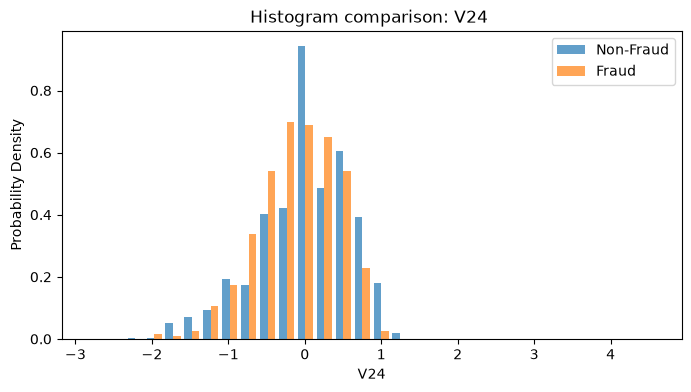

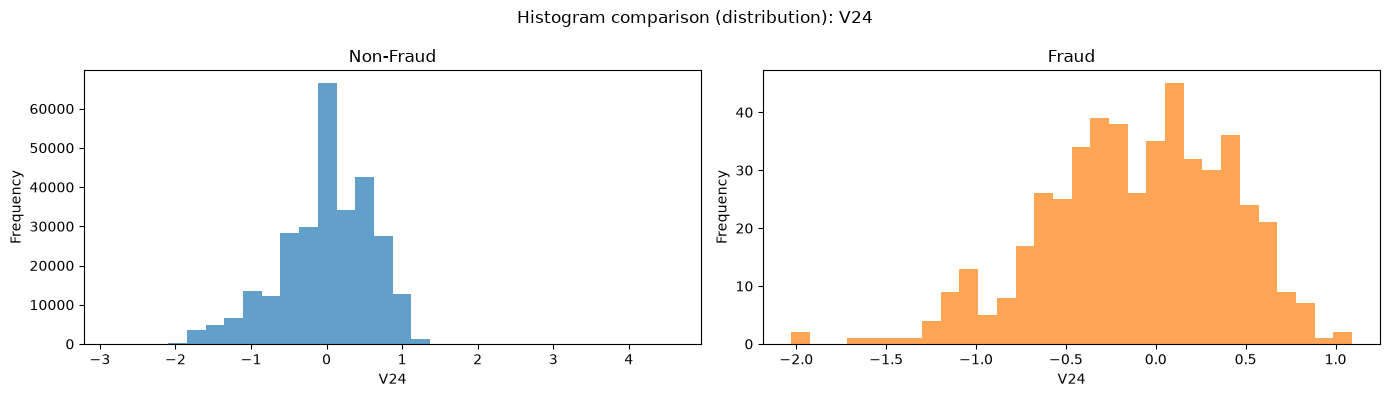

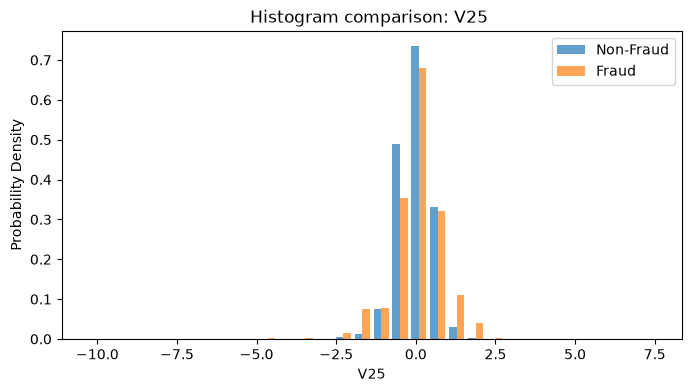

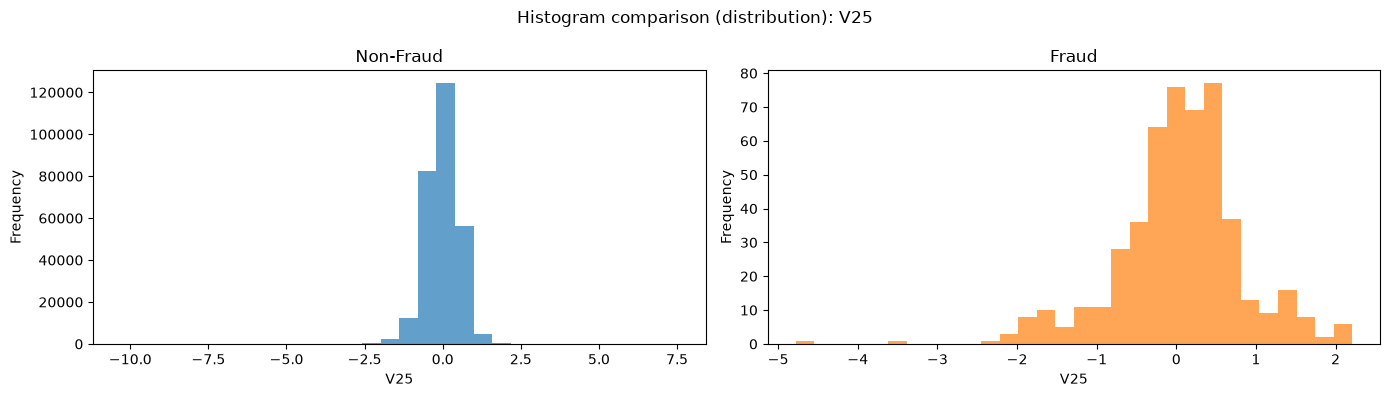

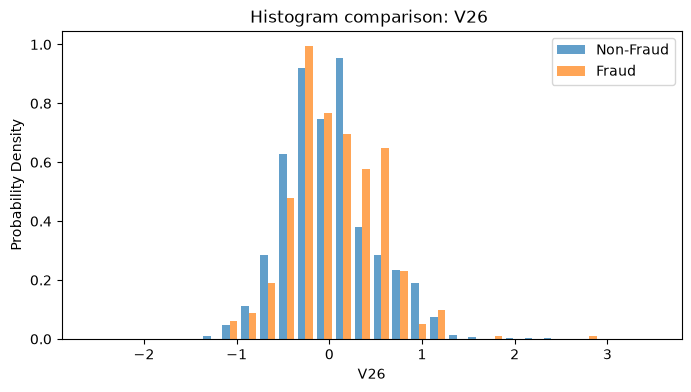

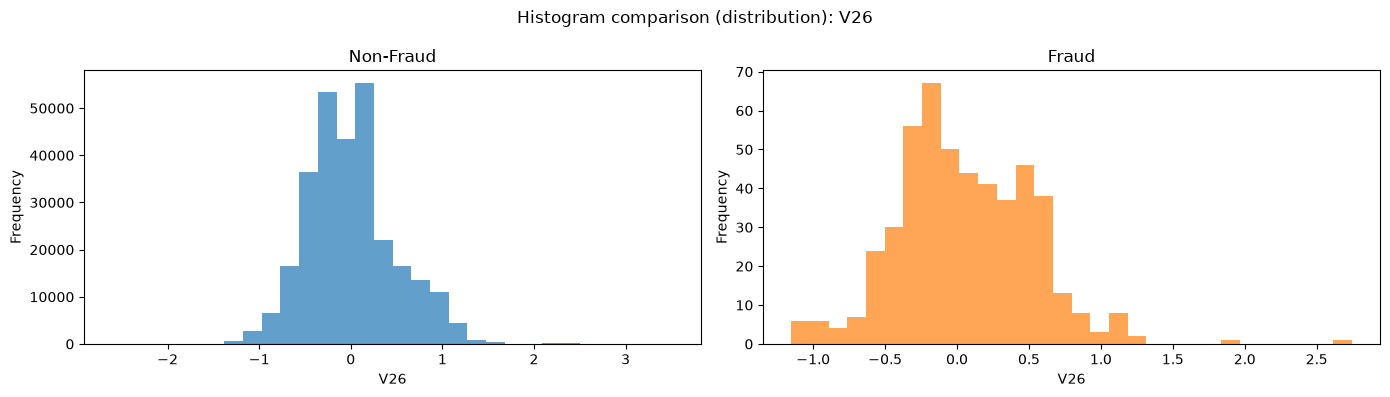

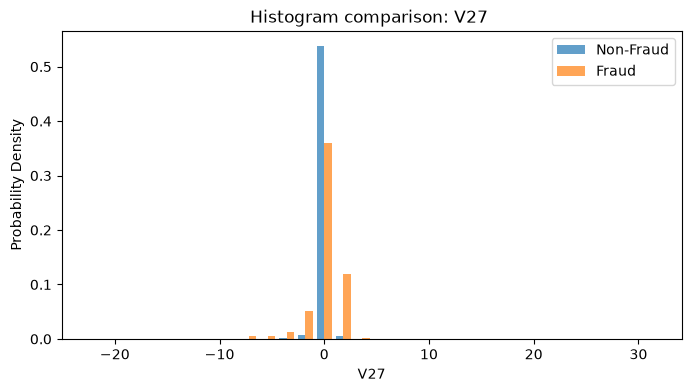

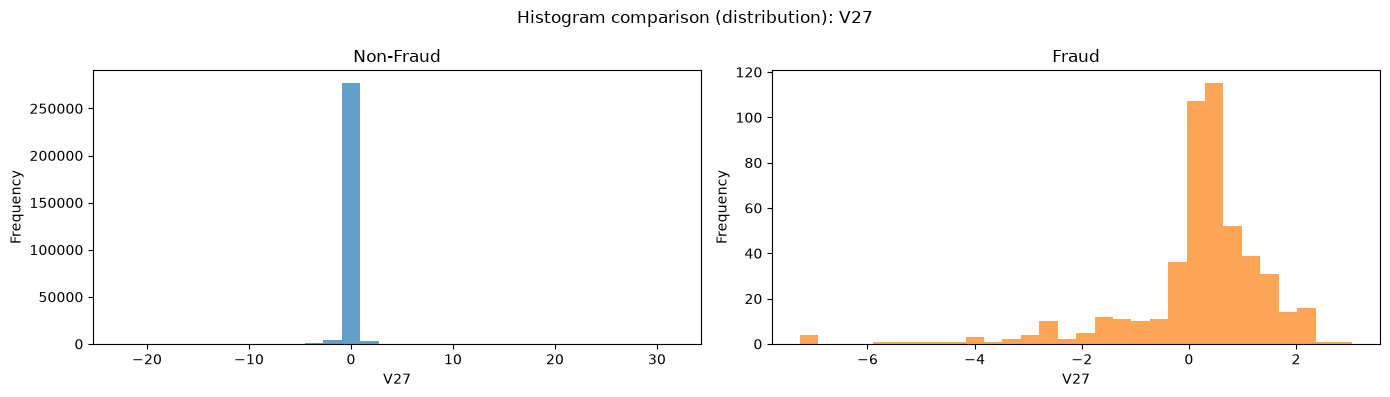

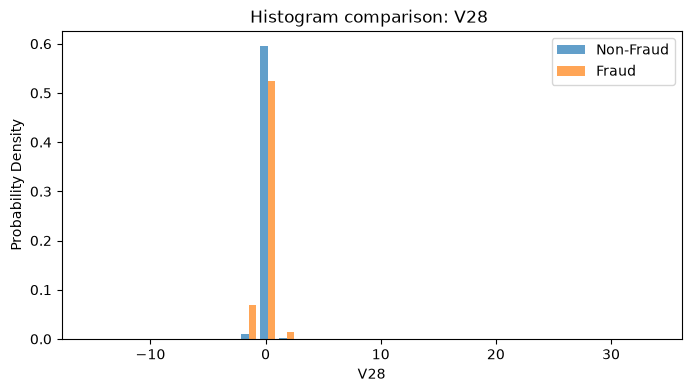

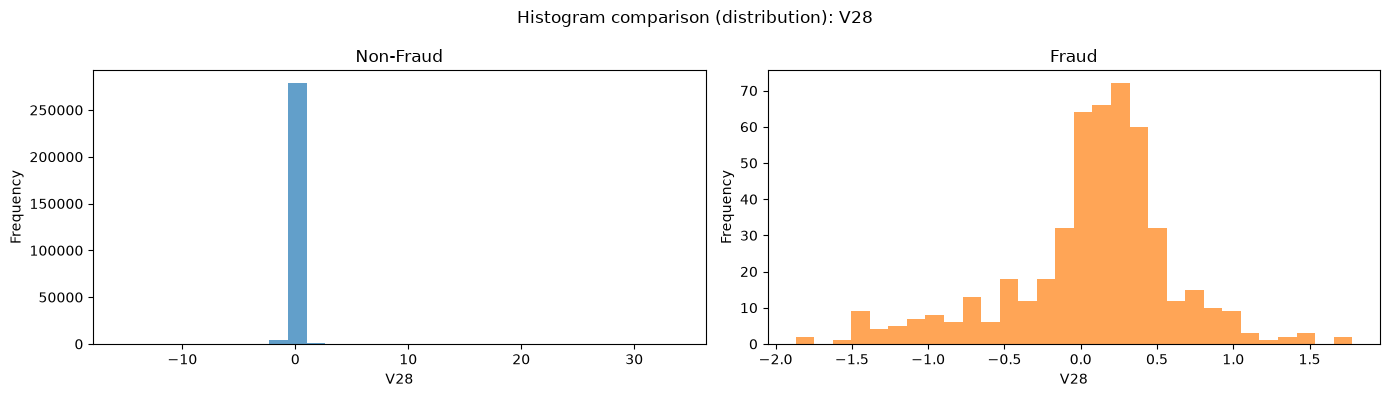

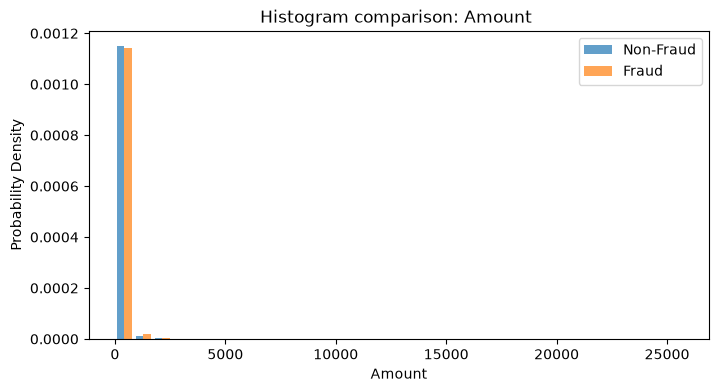

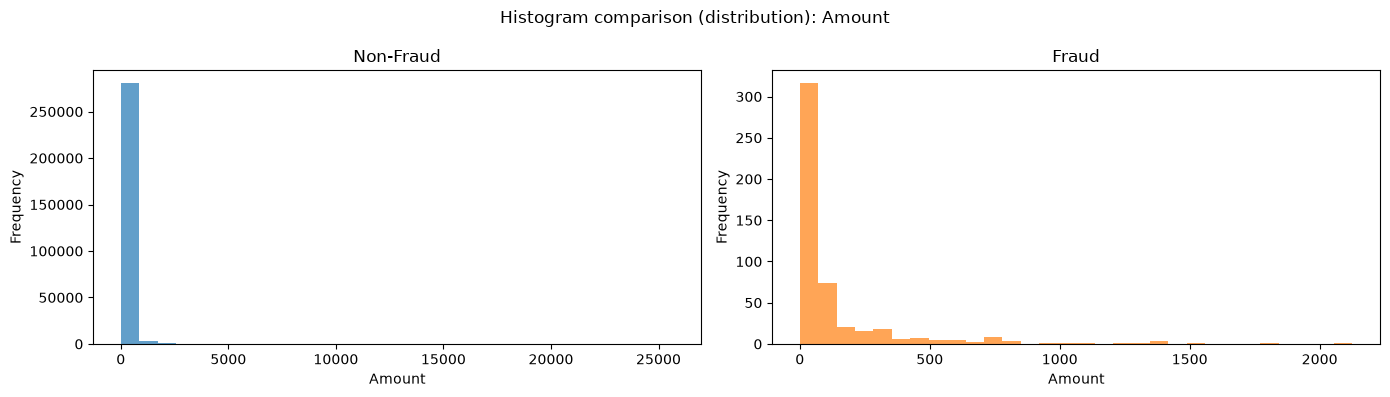

In [156]:
def histogram_comparison(df_1, df_2, column_drop:list=False, histogram_df_1_title="df_1", histogram_df_2_title="df_2", bins=30):

    if column_drop:
        if type(column_drop) is not list:
                raise TypeError("column_drop must be a list of column names to drop from both dataframes.")
        
        for col in column_drop:
            if col not in df_1.columns or col not in df_2.columns:
                raise KeyError(f"Column '{col}' not found in one or both of the dataframes.")
            df_1 = df_1.drop(columns=[col])
            df_2=df_2.drop(columns=[col])
    
    for col in df_1.columns:
        plt.figure(figsize=(8, 4))

        plt.hist(
            [
                df_1[col],
                df_2[col]
            ],
            bins=bins,
            label=[histogram_df_1_title, histogram_df_2_title],
            alpha=0.7,
            density=True

        )

        plt.title(f"Histogram comparison: {col} ")
        plt.xlabel(col)
        plt.ylabel("Probability Density")
        plt.legend()
        plt.show()

        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        axes[0].hist(df_1[col], bins=bins, alpha=0.7)
        axes[0].set_title(histogram_df_1_title)
        axes[0].set_xlabel(col)
        axes[0].set_ylabel("Frequency")

        axes[1].hist(df_2[col], bins=bins, alpha=0.7, color='C1')
        axes[1].set_title(histogram_df_2_title)
        axes[1].set_xlabel(col)
        axes[1].set_ylabel("Frequency")

        fig.suptitle(f"Histogram comparison (distribution): {col}")
        fig.tight_layout()
        plt.show()

histogram_comparison(
     credit_card_data_non_fraud,
     credit_card_data_fraud, 
     column_drop=["Class", "Time"], 
     histogram_df_1_title="Non-Fraud", 
     histogram_df_2_title="Fraud",
     bins=30
)

In [157]:
# Hour comparison between all data and without duplicates
credit_card_data_hour = credit_card_data.copy()
credit_card_data_hour["Time_hour"] = credit_card_data["Time"] // 3600
credit_card_data_hour["is_duplicate"] = credit_card_data_hour.duplicated()

transactions_by_hour = (
    credit_card_data_hour
    .groupby("Time_hour")
    .agg(
        transactions=("is_duplicate", "size"),
        duplicates=("is_duplicate", "sum"),
        frauds=("Class", "sum")
    )
    .reset_index()
)

transactions_by_hour["transactions_without_duplicates"] = (
    transactions_by_hour["transactions"]
    - transactions_by_hour["duplicates"]
)

frauds_without_duplicates = (
    credit_card_data_hour[~credit_card_data_hour["is_duplicate"]]
    .groupby("Time_hour")["Class"]
    .sum()
)

transactions_by_hour["frauds_without_duplicates"] = (
    transactions_by_hour["Time_hour"]
    .map(frauds_without_duplicates)
    .fillna(0)
)

transactions_by_hour["fraud_rate_percent"] = (
    transactions_by_hour["frauds"]
    / transactions_by_hour["transactions"]
    * 100
)

transactions_by_hour["fraud_rate_without_duplicates_percent"] = (
    transactions_by_hour["frauds_without_duplicates"]
    / transactions_by_hour["transactions_without_duplicates"]
    * 100
)

display(transactions_by_hour)



,Time_hour,transactions,duplicates,frauds,transactions_without_duplicates,frauds_without_duplicates,fraud_rate_percent,fraud_rate_without_duplicates_percent
0,0.0,3963,32,2,3931,2,0.050467,0.050878
1,1.0,2217,4,2,2213,2,0.090212,0.090375
2,2.0,1576,3,21,1573,21,1.332487,1.335029
3,3.0,1821,3,13,1818,13,0.713893,0.715072
4,4.0,1082,0,6,1082,6,0.554529,0.554529
5,5.0,1681,2,11,1679,11,0.654372,0.655152
6,6.0,1831,9,3,1822,3,0.163845,0.164654
7,7.0,3368,2,23,3366,23,0.682898,0.683304
8,8.0,5179,31,5,5148,5,0.096544,0.097125
9,9.0,7878,37,15,7841,15,0.190404,0.191302


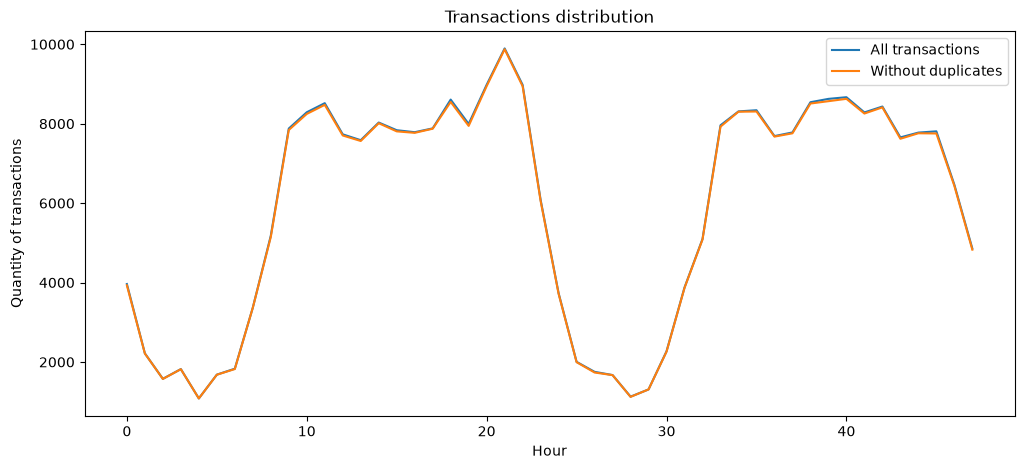

In [158]:
# Chart comaprison between all transaction and without duplicates
plt.figure(figsize=(12, 5))

plt.plot(
    transactions_by_hour["Time_hour"],
    transactions_by_hour["transactions"],
    label="All transactions"
)

plt.plot(
    transactions_by_hour["Time_hour"],
    transactions_by_hour["transactions_without_duplicates"],
    label="Without duplicates"
)

plt.xlabel("Hour")
plt.ylabel("Quantity of transactions")
plt.title("Transactions distribution")
plt.legend()
plt.show()

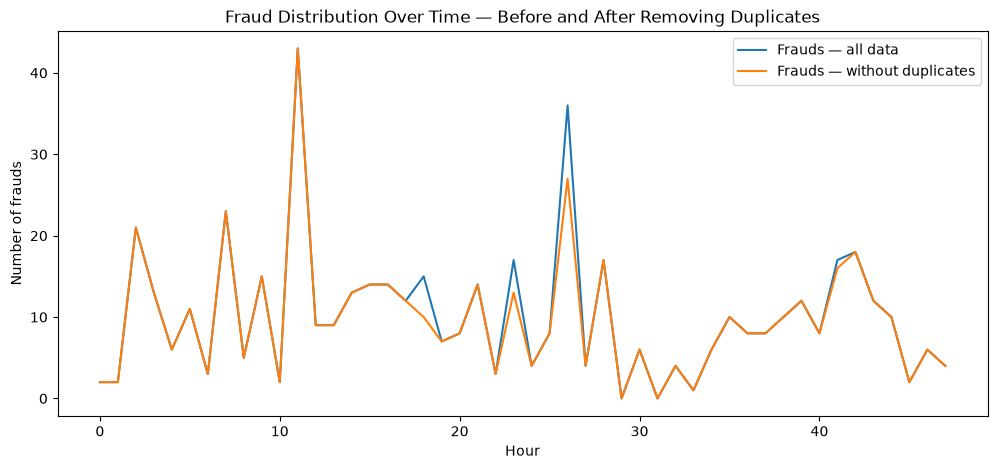

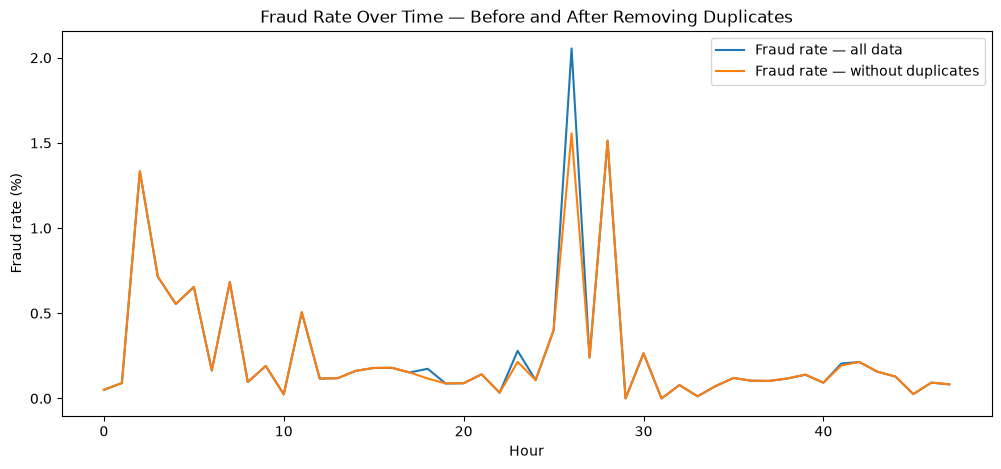

In [159]:
# Chart comparison between

plt.figure(figsize=(12, 5))

plt.plot(
    transactions_by_hour["Time_hour"],
    transactions_by_hour["frauds"],
    label="Frauds — all data"
)

plt.plot(
    transactions_by_hour["Time_hour"],
    transactions_by_hour["frauds_without_duplicates"],
    label="Frauds — without duplicates"
)

plt.xlabel("Hour")
plt.ylabel("Number of frauds")
plt.title("Fraud Distribution Over Time — Before and After Removing Duplicates")
plt.legend()
plt.show()

#fraud rate
plt.figure(figsize=(12, 5))

plt.plot(
    transactions_by_hour["Time_hour"],
    transactions_by_hour["fraud_rate_percent"],
    label="Fraud rate — all data"
)

plt.plot(
    transactions_by_hour["Time_hour"],
    transactions_by_hour["fraud_rate_without_duplicates_percent"],
    label="Fraud rate — without duplicates"
)

plt.xlabel("Hour")
plt.ylabel("Fraud rate (%)")
plt.title("Fraud Rate Over Time — Before and After Removing Duplicates")
plt.legend()
plt.show()

## Conclusion after Data Pre-Processing

After consideration statistic metrics noticed that there is no significant difference between all data and data without duplicates.
Transaction distribution by hour chart shows that there is no any peak caused by duplicates what can assume that duplicates are not target action.
Fraud rate chart has some two main frauds peak, but there is no any cyclicality.
Metrics for all data and data without duplicates shows that are meany statistic differences between most of features, 
it's good visible especially for comparison between non-fraud and fraud transactions what models can recognize.
Removal of duplicates do not affect at metrics that is not possible to spot any differences.
I can not get any information why dupplicates occured, 
**so basing on current information and the statistical data I decided to remove duplicates.**

In [160]:
credit_card_data_no_duplicates = credit_card_data.drop_duplicates()
display(credit_card_data_no_duplicates)

print("Original dataset:", credit_card_data.shape)
print("Without duplicates:", credit_card_data_no_duplicates.shape)
print("Removed rows:", credit_card_data.shape[0] - credit_card_data_no_duplicates.shape[0])

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


Original dataset: (284807, 31)
Without duplicates: (283726, 31)
Removed rows: 1081


# Data Split for train/valid/test

Choosen proportion for train/valid/test: 60/20/20.
Data split method is time-base.
If fraud rate will be similar at each set, above method will be applied, if not, will be used stratify method to keep similar fraud rate regardless of time.

In [161]:
credit_card_data_no_duplicates = (
    credit_card_data_no_duplicates
    .sort_values("Time")
    .reset_index(drop=True)
)

n = len(credit_card_data_no_duplicates)

train_end = int(n * 0.60)
valid_end = int(n * 0.80)

train_data = credit_card_data_no_duplicates.iloc[:train_end]
valid_data = credit_card_data_no_duplicates.iloc[train_end:valid_end]
test_data = credit_card_data_no_duplicates.iloc[valid_end:]

n = len(credit_card_data_no_duplicates)

train_end = int(n * 0.60)
valid_end = int(n * 0.80)

train_data = credit_card_data_no_duplicates.iloc[:train_end]
valid_data = credit_card_data_no_duplicates.iloc[train_end:valid_end]
test_data = credit_card_data_no_duplicates.iloc[valid_end:]

split_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Transactions": [
        len(train_data),
        len(valid_data),
        len(test_data)
    ],
    "Frauds": [
        train_data["Class"].sum(),
        valid_data["Class"].sum(),
        test_data["Class"].sum()
    ],
    "Fraud rate (%)": [
        train_data["Class"].mean() * 100,
        valid_data["Class"].mean() * 100,
        test_data["Class"].mean() * 100
    ]
})

display(split_summary)

,Dataset,Transactions,Frauds,Fraud rate (%)
0,Train,170235,342,0.200899
1,Validation,56745,57,0.100449
2,Test,56746,74,0.130406


## Conclusion
Fraud rate is different between sets, but there is no case that no fraud in some set. I would like to keep an information about transaction chronology because this is real case - model learns at older data to predcit frauds at newest data.

# Feature engineering
I decided to remove Time Column to protec model from learing frauds transaction basing on time (f.e the older transaction is the more frauds can be, etc.).
PCA was applied to feaures V1-V28 so I will not make more features.

In [162]:
#added Amount_log_column to each set, becasue amount has a big spread of values from small to big

train_data["Amount_log"] = np.log1p(train_data["Amount"])
valid_data["Amount_log"] = np.log1p(valid_data["Amount"])
test_data["Amount_log"] = np.log1p(test_data["Amount"])

# x,y for train, valid, test

X_train = train_data.drop(columns=["Class", "Time", "Amount"])
y_train = train_data["Class"]

X_valid = valid_data.drop(columns=["Class", "Time", "Amount"])
y_valid = valid_data["Class"]

X_test = test_data.drop(columns=["Class", "Time", "Amount"])
y_test = test_data["Class"]

print(X_train.columns)
print(X_train.shape)
print(y_train.shape)

Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11',
       'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21',
       'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount_log'],
      dtype='str')
(170235, 29)
(170235,)


# Experiments

The most important metric what was choose to select model - precesion. To avoid situation that bank workers check transaction as fraud and tourn out that is not fraud and need to apologize customer for issues.

## Experiment A - Logistic regression with standard scaler


### Train

In [163]:
def evaluate_model(model, X_valid, y_valid):
    y_pred = model.predict(X_valid)
    y_proba = model.predict_proba(X_valid)[:, 1]

    metrics = {
        "PR-AUC": average_precision_score(y_valid, y_proba),
        "Precision": precision_score(y_valid, y_pred),
        "Recall": recall_score(y_valid, y_pred),
        "F1": f1_score(y_valid, y_pred)
    }

    return metrics

In [164]:
def add_model_results(results_df, model_name, dataset_name, metrics):
    new_row = pd.DataFrame([{
        "Model": model_name,
        "Dataset": dataset_name,
        "PR-AUC": metrics["PR-AUC"],
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "F1": metrics["F1"]
    }])

    results_df = results_df[
        ~(
            (results_df["Model"] == model_name) &
            (results_df["Dataset"] == dataset_name)
        )
    ]

    results_df = pd.concat(
        [results_df, new_row],
        ignore_index=True
    )

    return results_df

results_df = pd.DataFrame(
    columns=[
        "Model",
        "Dataset",
        "PR-AUC",
        "Precision",
        "Recall",
        "F1"
    ]
)

In [165]:
def show_confusion_matrix(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Fraud"]
    )

    disp.plot()
    plt.show()

In [166]:
scaler = StandardScaler()

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [167]:
train_results = evaluate_model(
    logistic_model,
    X_train_scaled,
    y_train
)

train_results

results_df = add_model_results(
    results_df,
    "Logistic Regression",
    "Train",
    train_results
)

display(results_df)

,Model,Dataset,PR-AUC,Precision,Recall,F1
0,Logistic Regression,Train,0.763919,0.82996,0.599415,0.696095


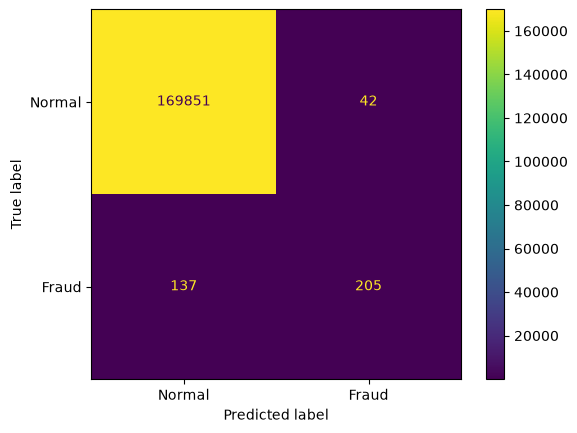

In [168]:
y_train_pred = logistic_model.predict(X_train_scaled)

show_confusion_matrix(
    y_train,
    y_train_pred
)

### Validation

In [169]:
X_valid_scaled = scaler.transform(X_valid)

valid_results = evaluate_model(
    logistic_model,
    X_valid_scaled,
    y_valid
)

valid_results

results_df = add_model_results(
    results_df,
    "Logistic Regression",
    "Validation",
    valid_results
)

display(results_df)

,Model,Dataset,PR-AUC,Precision,Recall,F1
0,Logistic Regression,Train,0.763919,0.82996,0.599415,0.696095
1,Logistic Regression,Validation,0.62356,0.642857,0.473684,0.545455


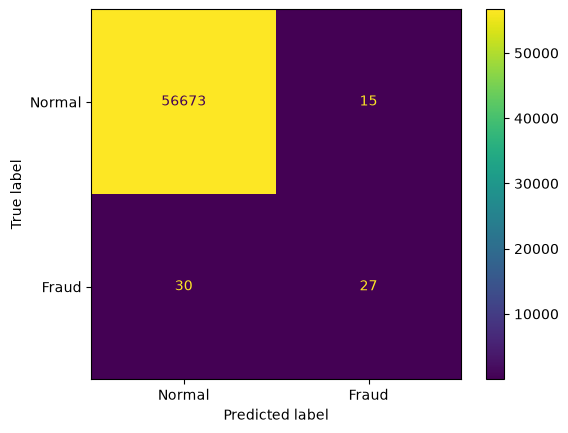

In [170]:
y_valid_pred = logistic_model.predict(X_valid_scaled)

show_confusion_matrix(
    y_valid,
    y_valid_pred
)

## Experiment B - Logistic regression with standard scaler + Balanced

### Train

In [171]:
logistic_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

logistic_balanced.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

In [172]:
balanced_train_results = evaluate_model(
    logistic_balanced,
    X_train_scaled,
    y_train
)

results_df = add_model_results(
    results_df,
    "Logistic Regression - Balanced",
    "Train",
    balanced_train_results
)

display(results_df)

,Model,Dataset,PR-AUC,Precision,Recall,F1
0,Logistic Regression,Train,0.763919,0.82996,0.599415,0.696095
1,Logistic Regression,Validation,0.62356,0.642857,0.473684,0.545455
2,Logistic Regression - Balanced,Train,0.732479,0.084878,0.923977,0.155474


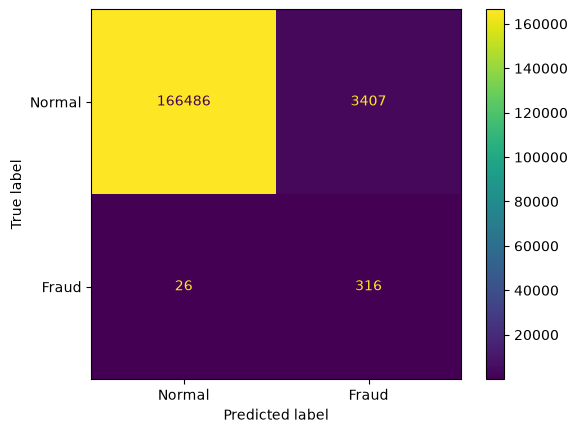

In [173]:
y_train_pred_balanced = logistic_balanced.predict(X_train_scaled)

show_confusion_matrix(
    y_train,
    y_train_pred_balanced
)

### Validation

In [174]:
valid_results = evaluate_model(
    logistic_model,
    X_valid_scaled,
    y_valid
)

results_df = add_model_results(
    results_df,
    "Logistic Regression",
    "Validation",
    valid_results
)

In [175]:
balanced_valid_results = evaluate_model(
    logistic_balanced,
    X_valid_scaled,
    y_valid
)

results_df = add_model_results(
    results_df,
    "Logistic Regression - Balanced",
    "Validation",
    balanced_valid_results
)

display(results_df)

,Model,Dataset,PR-AUC,Precision,Recall,F1
0,Logistic Regression,Train,0.763919,0.82996,0.599415,0.696095
1,Logistic Regression - Balanced,Train,0.732479,0.084878,0.923977,0.155474
2,Logistic Regression,Validation,0.62356,0.642857,0.473684,0.545455
3,Logistic Regression - Balanced,Validation,0.753208,0.024136,0.894737,0.047005


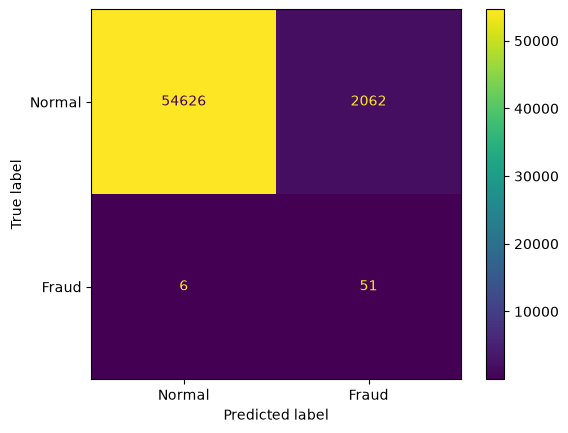

In [176]:
y_valid_pred_balanced = logistic_balanced.predict(X_valid_scaled)

show_confusion_matrix(
    y_valid,
    y_valid_pred_balanced
)

## Experiment C - Isolation Forest

### Train

In [177]:
def evaluate_anomaly_model(
    results_df,
    model,
    model_name,
    X,
    y_true,
    y_pred,
    dataset_name
):
    anomaly_score = -model.decision_function(X)

    metrics = {
        "PR-AUC": average_precision_score(y_true, anomaly_score),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred)
    }

    results_df = add_model_results(
        results_df,
        model_name,
        dataset_name,
        metrics
    )

    return results_df

In [178]:
isolation_forest = IsolationForest(
    random_state=42,
    contamination=0.5
)

isolation_forest.fit(X_train_scaled)

y_train_pred_if = isolation_forest.predict(X_train_scaled)

y_train_pred_if = (y_train_pred_if == -1).astype(int)

In [179]:
results_df = evaluate_anomaly_model(
    results_df,
    isolation_forest,
    "Isolation Forest",
    X_train_scaled,
    y_train,
    y_train_pred_if,
    "Train"
)
display(results_df)

,Model,Dataset,PR-AUC,Precision,Recall,F1
0,Logistic Regression,Train,0.763919,0.82996,0.599415,0.696095
1,Logistic Regression - Balanced,Train,0.732479,0.084878,0.923977,0.155474
2,Logistic Regression,Validation,0.62356,0.642857,0.473684,0.545455
3,Logistic Regression - Balanced,Validation,0.753208,0.024136,0.894737,0.047005
4,Isolation Forest,Train,0.249041,0.003854,0.959064,0.007676


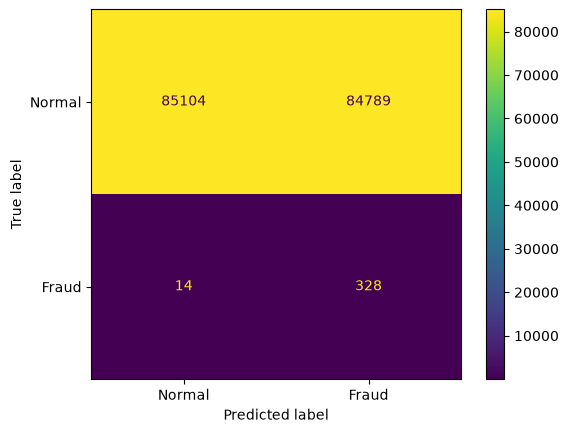

In [180]:
y_train_pred_if = isolation_forest.predict(X_train_scaled)
y_train_pred_if = (y_train_pred_if == -1).astype(int)

show_confusion_matrix(
    y_train,
    y_train_pred_if
)

### Validation



In [181]:
y_valid_pred_if = isolation_forest.predict(X_valid_scaled)

y_valid_pred_if = (y_valid_pred_if == -1).astype(int)



In [182]:
results_df = evaluate_anomaly_model(
    results_df,
    isolation_forest,
    "Isolation Forest",
    X_valid_scaled,
    y_valid,
    y_valid_pred_if,
    "Validation"
)

display(results_df)

,Model,Dataset,PR-AUC,Precision,Recall,F1
0,Logistic Regression,Train,0.763919,0.82996,0.599415,0.696095
1,Logistic Regression - Balanced,Train,0.732479,0.084878,0.923977,0.155474
2,Logistic Regression,Validation,0.62356,0.642857,0.473684,0.545455
3,Logistic Regression - Balanced,Validation,0.753208,0.024136,0.894737,0.047005
4,Isolation Forest,Train,0.249041,0.003854,0.959064,0.007676
5,Isolation Forest,Validation,0.018373,0.00142,0.982456,0.002837


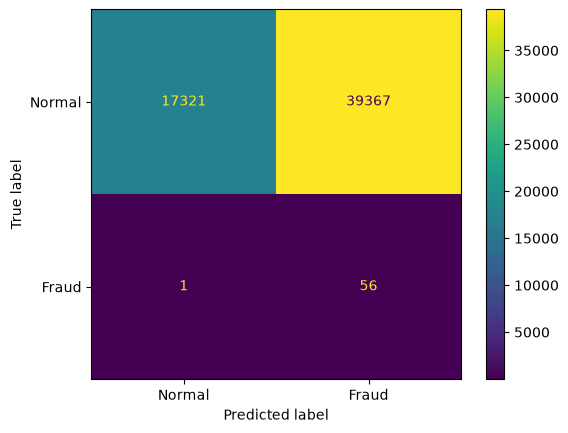

In [183]:
y_valid_pred_if = isolation_forest.predict(X_valid_scaled)
y_valid_pred_if = (y_valid_pred_if == -1).astype(int)

show_confusion_matrix(
    y_valid,
    y_valid_pred_if
)

# Test

### Experiment A was choosed as final model. Now will be checked at test set.

In [184]:
X_test_scaled = scaler.transform(X_test)

y_test_pred = logistic_model.predict(X_test_scaled)



In [185]:
test_results = evaluate_model(
    logistic_model,
    X_test_scaled,
    y_test
)

results_df = add_model_results(
    results_df,
    "Logistic Regression",
    "Test",
    test_results
)

display(results_df)

,Model,Dataset,PR-AUC,Precision,Recall,F1
0,Logistic Regression,Train,0.763919,0.82996,0.599415,0.696095
1,Logistic Regression - Balanced,Train,0.732479,0.084878,0.923977,0.155474
2,Logistic Regression,Validation,0.62356,0.642857,0.473684,0.545455
3,Logistic Regression - Balanced,Validation,0.753208,0.024136,0.894737,0.047005
4,Isolation Forest,Train,0.249041,0.003854,0.959064,0.007676
5,Isolation Forest,Validation,0.018373,0.00142,0.982456,0.002837
6,Logistic Regression,Test,0.694582,0.703704,0.513514,0.59375


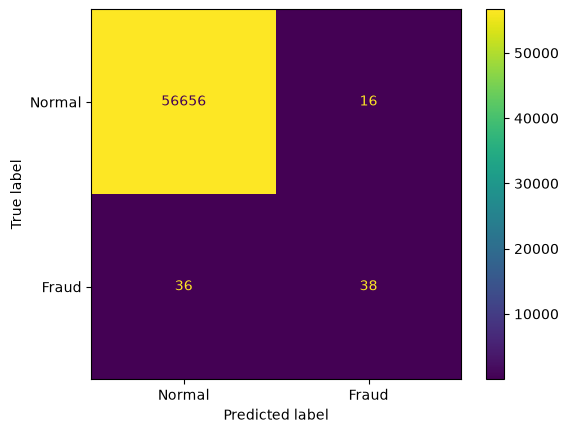

In [186]:
show_confusion_matrix(
    y_test,
    y_test_pred
)